In [1]:

import pandas as pd
import numpy as np
import time
import scipy
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Load datasets
train = pd.read_csv("UNSW_NB15_training-set.csv")
test = pd.read_csv("UNSW_NB15_testing-set.csv")

# Keep benign training observations only
train_benign = train[train["label"] == 0].copy()

# Preserve the complete official test partition
test_data = test.copy()
y_test = test_data["label"].values

# Exclude identifiers and labels from model features
excluded_columns = ["id", "attack_cat", "label"]

feature_columns = [
    col for col in train.columns
    if col not in excluded_columns
]

categorical_features = ["proto", "service", "state"]

numerical_features = [
    col for col in feature_columns
    if col not in categorical_features
]

# Experimental configuration
seeds = [0, 21, 42, 123, 2025]
target_fprs = [0.01, 0.03, 0.05, 0.10]

print("Training records:", len(train_benign))
print("Testing records:", len(test_data))
print("Features:", len(feature_columns))
print("Numerical:", len(numerical_features))
print("Categorical:", len(categorical_features))

print("\nPython libraries:")
print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)


Training records: 56000
Testing records: 82332
Features: 42
Numerical: 39
Categorical: 3

Python libraries:
Scikit-learn: 1.9.1
Pandas: 3.1.1
NumPy: 2.4.6
SciPy: 1.17.1


In [2]:

def prepare_experiment_data(seed):

    fit_benign, calibration_benign = train_test_split(
        train_benign,
        test_size=0.20,
        random_state=seed
    )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                StandardScaler(),
                numerical_features
            ),
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            )
        ]
    )

    X_fit = preprocessor.fit_transform(
        fit_benign[feature_columns]
    )

    X_calibration = preprocessor.transform(
        calibration_benign[feature_columns]
    )

    X_test = preprocessor.transform(
        test_data[feature_columns]
    )

    return X_fit, X_calibration, X_test


# Test the preparation pipeline
X_fit, X_calibration, X_test = prepare_experiment_data(42)

print("Fit:", X_fit.shape)
print("Calibration:", X_calibration.shape)
print("Test:", X_test.shape)


Fit: (44800, 64)
Calibration: (11200, 64)
Test: (82332, 64)


In [3]:

# Use a reproducible subset for the initial benchmark
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    X_fit.shape[0],
    size=5000,
    replace=False
)

X_lof_fit = X_fit[sample_indices]

lof = LocalOutlierFactor(
    n_neighbors=20,
    novelty=True,
    n_jobs=-1
)

start_time = time.time()

lof.fit(X_lof_fit)

training_time = time.time() - start_time

print("LOF training completed.")
print("Training time:", round(training_time, 2), "seconds")
print("Training observations:", X_lof_fit.shape[0])


LOF training completed.
Training time: 0.11 seconds
Training observations: 5000


In [4]:

def get_anomaly_scores(model, X, batch_size=2000):

    scores = []

    for start in range(0, X.shape[0], batch_size):

        end = min(start + batch_size, X.shape[0])

        batch = X[start:end]

        batch_scores = -model.score_samples(batch)

        scores.extend(batch_scores)

    return np.asarray(scores)


start_time = time.time()

calibration_scores = get_anomaly_scores(
    lof,
    X_calibration
)

test_scores = get_anomaly_scores(
    lof,
    X_test
)

scoring_time = time.time() - start_time

print("Calibration scores:", calibration_scores.shape)
print("Test scores:", test_scores.shape)
print("Scoring time:", round(scoring_time, 2), "seconds")

print("Calibration score range:",
      calibration_scores.min(),
      calibration_scores.max())

print("Test score range:",
      test_scores.min(),
      test_scores.max())


Calibration scores: (11200,)
Test scores: (82332,)
Scoring time: 1.16 seconds
Calibration score range: 0.9283263274009024 917870.0400158337
Test score range: 0.9180290819740445 351945.62341514573


In [5]:

# Inspect anomaly score distributions

print("CALIBRATION SCORES")
print(pd.Series(calibration_scores).describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
))

print("\nTEST SCORES")
print(pd.Series(test_scores).describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
))

print("\nFinite calibration scores:",
      np.isfinite(calibration_scores).all())

print("Finite test scores:",
      np.isfinite(test_scores).all())


CALIBRATION SCORES
count     11200.000000
mean        634.881007
std       13041.776795
min           0.928326
50%           1.042229
90%           1.352621
95%           1.671902
99%           5.135894
99.9%     77988.615966
max      917870.040016
dtype: float64

TEST SCORES
count     82332.000000
mean         69.975235
std        2748.925972
min           0.918029
50%           1.305287
90%           2.999050
95%           3.573259
99%           4.711639
99.9%        99.818267
max      351945.623415
dtype: float64

Finite calibration scores: True
Finite test scores: True


In [6]:

# Calculate thresholds using benign calibration observations

lof_results = []

for target_fpr in target_fprs:

    threshold = np.quantile(
        calibration_scores,
        1 - target_fpr
    )

    # Apply the threshold unchanged to test observations
    predictions = (
        test_scores >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    actual_fpr = fp / (fp + tn)
    detection_rate = tp / (tp + fn)

    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    alert_rate = predictions.mean()

    lof_results.append({
        "Target FPR": target_fpr,
        "Threshold": threshold,
        "Test FPR": actual_fpr,
        "Detection Rate": detection_rate,
        "Precision": precision,
        "F1": f1,
        "Alert Rate": alert_rate
    })

lof_results_df = pd.DataFrame(lof_results)

print(lof_results_df.to_string(index=False))


 Target FPR  Threshold  Test FPR  Detection Rate  Precision       F1  Alert Rate
       0.01   5.135894  0.009973        0.006397   0.440061 0.012611    0.008004
       0.03   2.140255  0.037973        0.330363   0.914230 0.485343    0.198963
       0.05   1.671902  0.073649        0.552854   0.901933 0.685513    0.337499
       0.10   1.352621  0.148351        0.732970   0.858224 0.790667    0.470242


In [7]:

lof_roc_auc = roc_auc_score(
    y_test,
    test_scores
)

lof_ap = average_precision_score(
    y_test,
    test_scores
)

print("LOF ROC-AUC:", lof_roc_auc)
print("LOF Average Precision:", lof_ap)


LOF ROC-AUC: 0.8644808720526755
LOF Average Precision: 0.8526963550611729


In [8]:

# Examine the extreme calibration scores

print("CALIBRATION EXTREME SCORE COUNTS")

for limit in [10, 100, 1000, 10000, 100000]:
    count = np.sum(calibration_scores > limit)
    print(f"Scores above {limit}: {count}")

# Show the 20 highest calibration scores
top_calibration_indices = np.argsort(
    calibration_scores
)[-20:][::-1]

print("\nTOP 20 CALIBRATION SCORES")

for idx in top_calibration_indices:
    print(idx, calibration_scores[idx])


# Examine test scores separately for benign and attack records
benign_test_scores = test_scores[y_test == 0]
attack_test_scores = test_scores[y_test == 1]

print("\nBENIGN TEST SCORE DISTRIBUTION")
print(pd.Series(benign_test_scores).describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
))

print("\nATTACK TEST SCORE DISTRIBUTION")
print(pd.Series(attack_test_scores).describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
))


CALIBRATION EXTREME SCORE COUNTS
Scores above 10: 89
Scores above 100: 63
Scores above 1000: 61
Scores above 10000: 61
Scores above 100000: 10

TOP 20 CALIBRATION SCORES
1524 917870.0400158337
2318 497478.717039096
2849 368399.82437516237
10220 347544.20227651607
8702 321199.440742312
9742 220743.53583982127
1022 216332.43577707605
3723 216332.43577682384
8543 177225.38022837712
9898 120333.7270855861
951 90846.99700255983
1933 77988.61596577735
9614 77988.61596577735
10842 77988.61596577735
8600 77988.61596577735
421 77988.61596577735
3404 77988.61596577735
9500 77988.61596577735
1711 77988.61596577735
2409 77988.61596577735

BENIGN TEST SCORE DISTRIBUTION
count     37000.000000
mean        153.090838
std        4099.090288
min           0.918029
50%           1.060341
90%           1.515146
95%           1.921578
99%           5.080291
99.9%     77988.615966
max      351945.623415
dtype: float64

ATTACK TEST SCORE DISTRIBUTION
count    45332.000000
mean         2.136240
std          

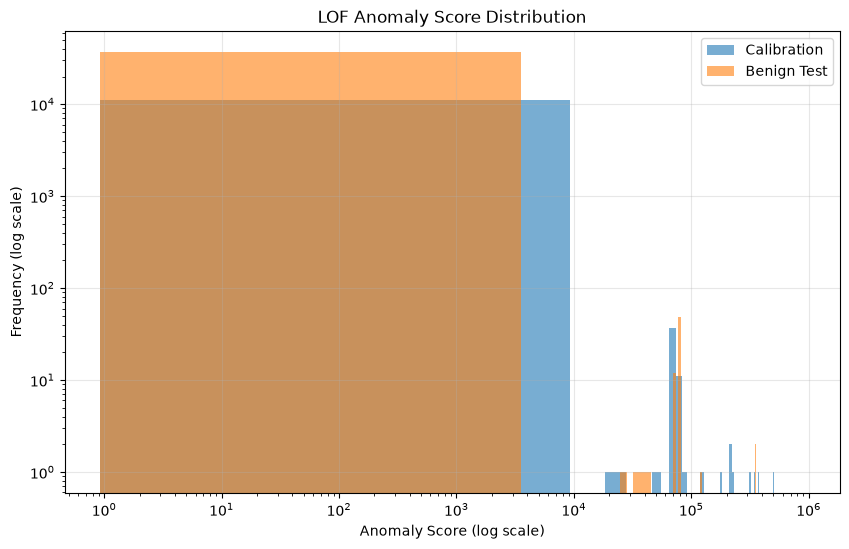

In [9]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    calibration_scores,
    bins=100,
    log=True,
    alpha=0.6,
    label="Calibration"
)

plt.hist(
    benign_test_scores,
    bins=100,
    log=True,
    alpha=0.6,
    label="Benign Test"
)

plt.xscale("log")
plt.xlabel("Anomaly Score (log scale)")
plt.ylabel("Frequency (log scale)")
plt.title("LOF Anomaly Score Distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [10]:

# Recreate the exact seed-42 calibration split

fit_benign_42, calibration_benign_42 = train_test_split(
    train_benign,
    test_size=0.20,
    random_state=42
)

# Find the 20 highest calibration anomaly scores
top_cal_indices = np.argsort(calibration_scores)[-20:][::-1]

# Recover the original records
top_cal_records = calibration_benign_42.iloc[
    top_cal_indices
].copy()

print("TOP 20 CALIBRATION OUTLIERS")
print(
    top_cal_records[
        ["id", "proto", "service", "state"]
    ].to_string(index=False)
)


TOP 20 CALIBRATION OUTLIERS
    id proto service state
107103   arp       -   INT
109201   arp       -   INT
109311   arp       -   INT
107138   arp       -   INT
107075   arp       -   INT
114644   arp       -   INT
112671   arp       -   INT
109812   arp       -   INT
115007   arp       -   INT
 43939   arp       -   INT
115133   arp       -   INT
 43203   arp       -   INT
 85015   arp       -   INT
109907   arp       -   INT
112099   arp       -   INT
 81934   arp       -   INT
112104   arp       -   INT
 43825   arp       -   INT
100638   arp       -   INT
 98564   arp       -   INT


In [11]:

# Find benign test observation positions
benign_positions = np.where(y_test == 0)[0]

# Sort them by anomaly score
top_benign_positions = benign_positions[
    np.argsort(test_scores[benign_positions])[-20:][::-1]
]

top_benign_records = test_data.iloc[
    top_benign_positions
].copy()

print("TOP 20 BENIGN TEST OUTLIERS")
print(
    top_benign_records[
        ["id", "proto", "service", "state"]
    ].to_string(index=False)
)


TOP 20 BENIGN TEST OUTLIERS
   id proto service state
70205   arp       -   INT
72159   arp       -   INT
43428   arp       -   INT
82251   arp       -   INT
77884   arp       -   INT
77061   arp       -   INT
80821   arp       -   INT
77060   arp       -   INT
68075   arp       -   INT
74295   arp       -   INT
82252   arp       -   INT
81177   arp       -   INT
81178   arp       -   INT
75647   arp       -   INT
42693   arp       -   INT
42992   arp       -   INT
43498   arp       -   INT
79959   arp       -   INT
79958   arp       -   INT
43499   arp       -   INT


In [12]:

# Compare extreme calibration observations with ordinary benign records

comparison_columns = numerical_features

extreme_numeric = top_cal_records[
    comparison_columns
].describe().loc[["mean", "min", "max"]]

ordinary_numeric = calibration_benign_42[
    comparison_columns
].describe().loc[["mean", "min", "max"]]

print("EXTREME OBSERVATION STATISTICS")
print(extreme_numeric.T)

print("\nALL CALIBRATION OBSERVATION STATISTICS")
print(ordinary_numeric.T)


EXTREME OBSERVATION STATISTICS
                           mean   min           max
dur                    0.000000   0.0      0.000000
spkts                  1.000000   1.0      1.000000
dpkts                  0.000000   0.0      0.000000
sbytes                46.000000  46.0     46.000000
dbytes                 0.000000   0.0      0.000000
rate                   0.000000   0.0      0.000000
sttl                   0.000000   0.0      0.000000
dttl                   0.000000   0.0      0.000000
sload                  0.000000   0.0      0.000000
dload                  0.000000   0.0      0.000000
sloss                  0.000000   0.0      0.000000
dloss                  0.000000   0.0      0.000000
sinpkt             33000.383600   0.0  60000.772000
dinpkt                 0.000000   0.0      0.000000
sjit                   2.190903   0.0     10.954521
djit                   0.000000   0.0      0.000000
swin                   0.000000   0.0      0.000000
stcpb                  0.000000  

In [13]:

# Reset indices to avoid index-alignment confusion

calibration_reset = calibration_benign_42.reset_index(drop=True)
test_reset = test_data.reset_index(drop=True)

# Calibration: top 20
cal_top_idx = np.argsort(calibration_scores)[-20:][::-1]

cal_top = calibration_reset.iloc[cal_top_idx].copy()
cal_top["lof_score"] = calibration_scores[cal_top_idx]

print("TOP 20 CALIBRATION RECORDS")
print(
    cal_top[
        ["id", "proto", "service", "state", "lof_score"]
    ].to_string(index=False)
)

# Test: top 20 benign records
benign_positions = np.flatnonzero(y_test == 0)

test_top_idx = benign_positions[
    np.argsort(test_scores[benign_positions])[-20:][::-1]
]

test_top = test_reset.iloc[test_top_idx].copy()
test_top["lof_score"] = test_scores[test_top_idx]

print("\nTOP 20 BENIGN TEST RECORDS")
print(
    test_top[
        ["id", "proto", "service", "state", "lof_score"]
    ].to_string(index=False)
)


TOP 20 CALIBRATION RECORDS
    id proto service state     lof_score
107103   arp       -   INT 917870.040016
109201   arp       -   INT 497478.717039
109311   arp       -   INT 368399.824375
107138   arp       -   INT 347544.202277
107075   arp       -   INT 321199.440742
114644   arp       -   INT 220743.535840
112671   arp       -   INT 216332.435777
109812   arp       -   INT 216332.435777
115007   arp       -   INT 177225.380228
 43939   arp       -   INT 120333.727086
115133   arp       -   INT  90846.997003
 43203   arp       -   INT  77988.615966
 85015   arp       -   INT  77988.615966
109907   arp       -   INT  77988.615966
112099   arp       -   INT  77988.615966
 81934   arp       -   INT  77988.615966
112104   arp       -   INT  77988.615966
 43825   arp       -   INT  77988.615966
100638   arp       -   INT  77988.615966
 98564   arp       -   INT  77988.615966

TOP 20 BENIGN TEST RECORDS
   id proto service state     lof_score
70205   arp       -   INT 351945.623415
7215

In [14]:

print("PROTOCOL FREQUENCIES")

print("\nModel-fitting subset:")
print(
    fit_benign_42["proto"].value_counts().head(15)
)

print("\nCalibration subset:")
print(
    calibration_benign_42["proto"].value_counts().head(15)
)

print("\nBenign test subset:")
print(
    test_data.loc[y_test == 0, "proto"].value_counts().head(15)
)

print("\nARP counts:")
print("Fit:", (fit_benign_42["proto"] == "arp").sum())
print("Calibration:", (calibration_benign_42["proto"] == "arp").sum())
print("Benign test:", (test_data.loc[y_test == 0, "proto"] == "arp").sum())


PROTOCOL FREQUENCIES

Model-fitting subset:
proto
tcp     31342
udp     11084
arp      2292
ospf       52
igmp       16
icmp       13
rtp         1
Name: count, dtype: int64

Calibration subset:
proto
tcp     7779
udp     2838
arp      567
ospf      12
igmp       2
icmp       2
Name: count, dtype: int64

Benign test subset:
proto
tcp     27848
udp      8097
arp       987
ospf       38
igmp       30
Name: count, dtype: int64

ARP counts:
Fit: 2292
Calibration: 567
Benign test: 987


In [15]:

# Compare numerical features of extreme ARP records
# against all benign calibration observations.

arp_extreme = cal_top[
    cal_top["proto"] == "arp"
]

print("Extreme ARP records:", len(arp_extreme))

print("\nExtreme ARP numerical statistics:")
print(arp_extreme[numerical_features].describe().T)

print("\nAll benign calibration numerical statistics:")
print(
    calibration_benign_42[numerical_features]
    .describe()
    .T
)


Extreme ARP records: 20

Extreme ARP numerical statistics:
                   count          mean           std   min   25%       50%  \
dur                 20.0      0.000000      0.000000   0.0   0.0      0.00   
spkts               20.0      1.000000      0.000000   1.0   1.0      1.00   
dpkts               20.0      0.000000      0.000000   0.0   0.0      0.00   
sbytes              20.0     46.000000      0.000000  46.0  46.0     46.00   
dbytes              20.0      0.000000      0.000000   0.0   0.0      0.00   
rate                20.0      0.000000      0.000000   0.0   0.0      0.00   
sttl                20.0      0.000000      0.000000   0.0   0.0      0.00   
dttl                20.0      0.000000      0.000000   0.0   0.0      0.00   
sload               20.0      0.000000      0.000000   0.0   0.0      0.00   
dload               20.0      0.000000      0.000000   0.0   0.0      0.00   
sloss               20.0      0.000000      0.000000   0.0   0.0      0.00   
dloss

In [16]:

# How many ARP records were actually used by LOF?

lof_fit_records = fit_benign_42.iloc[sample_indices].copy()

print("ARP in complete fitting subset:",
      (fit_benign_42["proto"] == "arp").sum())

print("ARP in actual LOF training sample:",
      (lof_fit_records["proto"] == "arp").sum())

print("ARP in calibration:",
      (calibration_benign_42["proto"] == "arp").sum())

print("ARP in benign test:",
      (test_data.loc[y_test == 0, "proto"] == "arp").sum())


ARP in complete fitting subset: 2292
ARP in actual LOF training sample: 258
ARP in calibration: 567
ARP in benign test: 987


In [17]:

fit_arp = fit_benign_42[
    fit_benign_42["proto"] == "arp"
]

cal_arp = calibration_benign_42[
    calibration_benign_42["proto"] == "arp"
]

test_arp = test_data[
    (test_data["proto"] == "arp") &
    (test_data["label"] == 0)
]

features_to_inspect = [
    "dur", "spkts", "dpkts",
    "sbytes", "dbytes", "sinpkt",
    "sjit", "ct_srv_src", "ct_dst_src_ltm"
]

for name, data in [
    ("FITTING ARP", fit_arp),
    ("CALIBRATION ARP", cal_arp),
    ("TEST ARP", test_arp)
]:

    print(f"\n{name}: {len(data)} records")

    print(
        data[features_to_inspect].describe(
            percentiles=[0.50, 0.90, 0.99]
        ).loc[
            ["mean", "50%", "90%", "99%", "max"]
        ].round(3)
    )



FITTING ARP: 2292 records
         dur   spkts  dpkts   sbytes   dbytes     sinpkt       sjit  \
mean   4.067   1.115  0.091   50.517    3.315  53750.947    176.828   
50%    0.000   1.000  0.000   46.000    0.000  60000.680      0.000   
90%    0.000   1.000  0.000   46.000    0.000  60000.792     15.492   
99%   59.997   4.000  4.000  184.000  112.000  60001.212  15212.777   
max   60.000  14.000  4.000  644.000  138.000  60009.912  15516.663   

      ct_srv_src  ct_dst_src_ltm  
mean       1.791           1.788  
50%        2.000           2.000  
90%        2.000           2.000  
99%        4.000           4.000  
max        8.000           8.000  

CALIBRATION ARP: 567 records
         dur   spkts  dpkts   sbytes   dbytes     sinpkt       sjit  \
mean   4.464   1.145  0.056   52.303    1.929  54225.386    140.650   
50%    0.000   1.000  0.000   46.000    0.000  60000.688      0.000   
90%    0.000   1.000  0.000   46.000    0.000  60000.794     15.492   
99%   59.998   4.000  

In [18]:

top_indices = np.argsort(calibration_scores)[-20:][::-1]

X_extreme = X_calibration[top_indices]

distances, neighbours = lof.kneighbors(
    X_extreme,
    n_neighbors=20
)

print("NEAREST NEIGHBOUR DISTANCES")

for i in range(len(top_indices)):
    print(
        f"Observation {top_indices[i]} | "
        f"LOF score: {calibration_scores[top_indices[i]]:.2f} | "
        f"Nearest distance: {distances[i, 0]:.4f} | "
        f"Mean 20-neighbour distance: {distances[i].mean():.4f}"
    )


NEAREST NEIGHBOUR DISTANCES
Observation 1524 | LOF score: 917870.04 | Nearest distance: 1.0201 | Mean 20-neighbour distance: 2.2063
Observation 2318 | LOF score: 497478.72 | Nearest distance: 1.1549 | Mean 20-neighbour distance: 1.2028
Observation 2849 | LOF score: 368399.82 | Nearest distance: 1.1549 | Mean 20-neighbour distance: 1.2028
Observation 10220 | LOF score: 347544.20 | Nearest distance: 0.7709 | Mean 20-neighbour distance: 1.8973
Observation 8702 | LOF score: 321199.44 | Nearest distance: 0.0002 | Mean 20-neighbour distance: 1.2792
Observation 9742 | LOF score: 220743.54 | Nearest distance: 0.0000 | Mean 20-neighbour distance: 0.3277
Observation 1022 | LOF score: 216332.44 | Nearest distance: 0.0000 | Mean 20-neighbour distance: 0.3277
Observation 3723 | LOF score: 216332.44 | Nearest distance: 0.0000 | Mean 20-neighbour distance: 0.3277
Observation 8543 | LOF score: 177225.38 | Nearest distance: 0.0000 | Mean 20-neighbour distance: 0.3277
Observation 9898 | LOF score: 12033

In [19]:
# Check duplicate rows in the actual LOF training data

X_lof_dense = np.asarray(X_lof_fit)

unique_rows = np.unique(X_lof_dense, axis=0)

print("Total LOF training observations:", len(X_lof_dense))
print("Unique feature vectors:", len(unique_rows))
print("Duplicate observations:",
      len(X_lof_dense) - len(unique_rows))

# Check duplicate ARP records separately
lof_fit_records = fit_benign_42.iloc[sample_indices].copy()

arp_mask = lof_fit_records["proto"].values == "arp"

X_arp = X_lof_dense[arp_mask]

print("\nARP training observations:", len(X_arp))
print("Unique ARP feature vectors:",
      len(np.unique(X_arp, axis=0)))
print("Duplicate ARP vectors:",
      len(X_arp) - len(np.unique(X_arp, axis=0)))

Total LOF training observations: 5000
Unique feature vectors: 4871
Duplicate observations: 129

ARP training observations: 258
Unique ARP feature vectors: 165
Duplicate ARP vectors: 93


In [20]:

# Inspect the fitted model's local reachability densities

print("LOF fitted neighbourhood information")

print("Training k-distance shape:",
      lof._distances_fit_X_.shape)

print("Local reachability density shape:",
      lof._lrd.shape)

print("\nTraining k-distance statistics:")
print(pd.Series(lof._distances_fit_X_.ravel()).describe(
    percentiles=[0.50, 0.90, 0.99, 0.999]
))

print("\nLocal reachability density statistics:")
print(pd.Series(lof._lrd).describe(
    percentiles=[0.50, 0.90, 0.99, 0.999]
))


LOF fitted neighbourhood information
Training k-distance shape: (5000, 20)
Local reachability density shape: (5000,)

Training k-distance statistics:
count    100000.000000
mean          1.525827
std           1.962274
min           0.000000
50%           1.212822
90%           2.582138
99%           8.930659
99.9%        27.391904
max          43.581695
dtype: float64

Local reachability density statistics:
count      5000.000000
mean      13417.872589
std       78230.915356
min           0.026242
50%           0.705173
90%           2.195076
99%      456632.284053
99.9%    694634.011161
max      694634.011161
dtype: float64


In [21]:

# Compare LOF scores and local density-related quantities

top_indices = np.argsort(calibration_scores)[-10:][::-1]

X_extreme = X_calibration[top_indices]

distances, neighbours = lof.kneighbors(
    X_extreme,
    n_neighbors=20
)

# Query local reachability densities, as used in novelty scoring
query_lrd = lof._local_reachability_density(
    distances,
    neighbours
)

print("EXTREME OBSERVATIONS")

for i, idx in enumerate(top_indices):

    print(
        f"Index: {idx} | "
        f"Score: {calibration_scores[idx]:.2f} | "
        f"Mean distance: {distances[i].mean():.6f} | "
        f"Query LRD: {query_lrd[i]:.8f} | "
        f"Neighbour LRD mean: {lof._lrd[neighbours[i]].mean():.8f}"
    )


EXTREME OBSERVATIONS
Index: 1524 | Score: 917870.04 | Mean distance: 2.206255 | Query LRD: 0.44982766 | Neighbour LRD mean: 412883.33094928
Index: 2318 | Score: 497478.72 | Mean distance: 1.202810 | Query LRD: 0.83138667 | Neighbour LRD mean: 413597.17526399
Index: 2849 | Score: 368399.82 | Mean distance: 1.202810 | Query LRD: 0.83138667 | Neighbour LRD mean: 306282.70418386
Index: 10220 | Score: 347544.20 | Mean distance: 1.897273 | Query LRD: 0.51906249 | Neighbour LRD mean: 180397.15971769
Index: 8702 | Score: 321199.44 | Mean distance: 1.279186 | Query LRD: 0.74239245 | Neighbour LRD mean: 238456.03818055
Index: 9742 | Score: 220743.54 | Mean distance: 0.327718 | Query LRD: 2.89883192 | Neighbour LRD mean: 639898.40846518
Index: 1022 | Score: 216332.44 | Mean distance: 0.327718 | Query LRD: 2.89883192 | Neighbour LRD mean: 627111.37078866
Index: 3723 | Score: 216332.44 | Mean distance: 0.327718 | Query LRD: 2.89883192 | Neighbour LRD mean: 627111.37078866
Index: 8543 | Score: 17722

In [22]:

# Inspect the nearest training neighbours of the worst observation

worst_idx = np.argmax(calibration_scores)

X_worst = X_calibration[worst_idx].reshape(1, -1)

distances, neighbour_indices = lof.kneighbors(
    X_worst,
    n_neighbors=20
)

neighbour_indices = neighbour_indices[0]
distances = distances[0]

neighbour_records = lof_fit_records.iloc[
    neighbour_indices
].copy()

neighbour_records["distance"] = distances
neighbour_records["training_lrd"] = lof._lrd[neighbour_indices]

print("WORST CALIBRATION OBSERVATION")
print("Index:", worst_idx)
print("Score:", calibration_scores[worst_idx])

print("\nITS 20 NEAREST TRAINING NEIGHBOURS")

print(
    neighbour_records[
        ["id", "proto", "service", "state",
         "distance", "training_lrd"]
    ].to_string(index=False)
)


WORST CALIBRATION OBSERVATION
Index: 1524
Score: 917870.0400158337

ITS 20 NEAREST TRAINING NEIGHBOURS
    id proto service state  distance  training_lrd
107081   arp       -   INT  1.020057      0.742392
114651   arp       -   INT  2.060929      2.898832
114795   arp       -   INT  2.280229 459972.656168
113311   arp       -   INT  2.280229 459972.656168
114790   arp       -   INT  2.280229 459972.656168
114034   arp       -   INT  2.280229 459972.656168
112148   arp       -   INT  2.280229 470402.483171
111178   arp       -   INT  2.280229 456632.284053
111023   arp       -   INT  2.280229 456632.284053
111886   arp       -   INT  2.280229 456632.284053
113633   arp       -   INT  2.280229 446829.119881
111948   arp       -   INT  2.280229 446829.119881
110719   arp       -   INT  2.280229 446829.119881
110718   arp       -   INT  2.280229 446829.119881
111185   arp       -   INT  2.280229 446829.119881
113634   arp       -   INT  2.280229 446829.119881
110430   arp       -   INT  2.

In [23]:

# Count zero-distance and near-zero-distance neighbours

print("Nearest-neighbour distance analysis")

for threshold in [0, 1e-8, 1e-5, 1e-3, 0.01]:
    count = np.sum(distances <= threshold)
    print(f"Distance <= {threshold}: {count}")

print("\nNeighbour protocol distribution:")
print(neighbour_records["proto"].value_counts())

print("\nNeighbour local reachability densities:")
print(
    pd.Series(neighbour_records["training_lrd"]).describe()
)


Nearest-neighbour distance analysis
Distance <= 0: 0
Distance <= 1e-08: 0
Distance <= 1e-05: 0
Distance <= 0.001: 0
Distance <= 0.01: 0

Neighbour protocol distribution:
proto
arp    20
Name: count, dtype: int64

Neighbour local reachability densities:
count        20.000000
mean     412883.330949
std      147138.238731
min           0.742392
25%      442245.043582
50%      446829.119881
75%      459972.656168
max      625199.230084
Name: training_lrd, dtype: float64


In [24]:

# Inspect the training neighbourhoods of the 20 nearest neighbours

for rank, idx in enumerate(neighbour_indices):

    point = X_lof_fit[idx].reshape(1, -1)

    dists, inds = lof.kneighbors(
        point,
        n_neighbors=21
    )

    d = dists[0]
    ix = inds[0]

    # Remove the observation itself
    mask = ix != idx
    d = d[mask][:20]
    ix = ix[mask][:20]

    print(f"\nNeighbour rank: {rank + 1}")
    print("Training ID:",
          lof_fit_records.iloc[idx]["id"])
    print("Training LRD:", lof._lrd[idx])
    print("Minimum neighbour distance:", d.min())
    print("Zero-distance neighbours:", np.sum(d == 0))
    print("Near-zero neighbours:", np.sum(d < 1e-5))
    print("Mean neighbour distance:", d.mean())



Neighbour rank: 1
Training ID: 107081
Training LRD: 0.7423924456815303
Minimum neighbour distance: 1.167853282203148
Zero-distance neighbours: 0
Near-zero neighbours: 0
Mean neighbour distance: 1.34699646493269

Neighbour rank: 2
Training ID: 114651
Training LRD: 2.8988319228949537
Minimum neighbour distance: 0.34496653352270307
Zero-distance neighbours: 0
Near-zero neighbours: 0
Mean neighbour distance: 0.3449665335241037

Neighbour rank: 3
Training ID: 114795
Training LRD: 459972.65616777644
Minimum neighbour distance: 0.0
Zero-distance neighbours: 3
Near-zero neighbours: 20
Mean neighbour distance: 8.236904046531687e-07

Neighbour rank: 4
Training ID: 113311
Training LRD: 459972.65616777644
Minimum neighbour distance: 0.0
Zero-distance neighbours: 3
Near-zero neighbours: 20
Mean neighbour distance: 8.236904046531687e-07

Neighbour rank: 5
Training ID: 114790
Training LRD: 459972.65616777644
Minimum neighbour distance: 0.0
Zero-distance neighbours: 3
Near-zero neighbours: 20
Mean ne

In [25]:

# Remove exact duplicate feature vectors for diagnostic purposes

X_lof_unique, unique_indices, duplicate_counts = np.unique(
    X_lof_fit,
    axis=0,
    return_index=True,
    return_counts=True
)

print("Original training size:", len(X_lof_fit))
print("Unique training size:", len(X_lof_unique))
print("Removed duplicates:", len(X_lof_fit) - len(X_lof_unique))

print("Largest duplicate group:", duplicate_counts.max())


Original training size: 5000
Unique training size: 4871
Removed duplicates: 129
Largest duplicate group: 10


In [26]:

lof_deduplicated = LocalOutlierFactor(
    n_neighbors=20,
    novelty=True,
    n_jobs=-1
)

start_time = time.time()

lof_deduplicated.fit(X_lof_unique)

print(
    "Deduplicated LOF training time:",
    round(time.time() - start_time, 2),
    "seconds"
)


Deduplicated LOF training time: 0.07 seconds


In [27]:

calibration_scores_dedup = get_anomaly_scores(
    lof_deduplicated,
    X_calibration
)

test_scores_dedup = get_anomaly_scores(
    lof_deduplicated,
    X_test
)

print("Calibration score distribution:")
print(pd.Series(calibration_scores_dedup).describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
))

print("\nTest score distribution:")
print(pd.Series(test_scores_dedup).describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
))


Calibration score distribution:
count     11200.000000
mean       1515.133104
std       21596.629518
min           0.928255
50%           1.039746
90%           1.342105
95%           1.638064
99%           5.604559
99.9%    325486.380362
max      384224.459331
dtype: float64

Test score distribution:
count     82332.000000
mean        232.004185
std        8381.166926
min           0.926690
50%           1.306954
90%           2.850308
95%           3.538203
99%           4.810420
99.9%       101.178664
max      325486.380362
dtype: float64


In [28]:

comparison = []

for model_name, cal_scores, scores in [
    ("Original LOF", calibration_scores, test_scores),
    ("Deduplicated LOF", calibration_scores_dedup, test_scores_dedup)
]:

    roc = roc_auc_score(y_test, scores)
    ap = average_precision_score(y_test, scores)

    for target_fpr in target_fprs:

        threshold = np.quantile(
            cal_scores,
            1 - target_fpr
        )

        predictions = (scores >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test,
            predictions,
            labels=[0, 1]
        ).ravel()

        comparison.append({
            "Model": model_name,
            "Target FPR": target_fpr,
            "ROC-AUC": roc,
            "Average Precision": ap,
            "Actual FPR": fp / (fp + tn),
            "Detection Rate": tp / (tp + fn),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_test, predictions, zero_division=0
            )
        })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4).to_string(index=False))


           Model  Target FPR  ROC-AUC  Average Precision  Actual FPR  Detection Rate  Precision     F1
    Original LOF        0.01   0.8645             0.8527      0.0100          0.0064     0.4401 0.0126
    Original LOF        0.03   0.8645             0.8527      0.0380          0.3304     0.9142 0.4853
    Original LOF        0.05   0.8645             0.8527      0.0736          0.5529     0.9019 0.6855
    Original LOF        0.10   0.8645             0.8527      0.1484          0.7330     0.8582 0.7907
Deduplicated LOF        0.01   0.8639             0.8518      0.0095          0.0049     0.3839 0.0096
Deduplicated LOF        0.03   0.8639             0.8518      0.0361          0.3106     0.9133 0.4636
Deduplicated LOF        0.05   0.8639             0.8518      0.0765          0.5671     0.9009 0.6961
Deduplicated LOF        0.10   0.8639             0.8518      0.1508          0.7337     0.8563 0.7903


In [29]:

lof_sensitivity_results = []

for k in [10, 20, 35]:

    print(f"\nTraining LOF with n_neighbors={k}")

    model = LocalOutlierFactor(
        n_neighbors=k,
        novelty=True,
        n_jobs=-1
    )

    start = time.time()
    model.fit(X_lof_fit)
    train_time = time.time() - start

    cal_scores = get_anomaly_scores(
        model, X_calibration
    )

    scores = get_anomaly_scores(
        model, X_test
    )

    roc = roc_auc_score(y_test, scores)
    ap = average_precision_score(y_test, scores)

    for target in target_fprs:

        threshold = np.quantile(
            cal_scores, 1 - target
        )

        predictions = (scores >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test,
            predictions,
            labels=[0, 1]
        ).ravel()

        lof_sensitivity_results.append({
            "k": k,
            "Target FPR": target,
            "ROC-AUC": roc,
            "Average Precision": ap,
            "Actual FPR": fp / (fp + tn),
            "Detection Rate": tp / (tp + fn),
            "Training Time": train_time,
            "Calibration Max": cal_scores.max()
        })

sensitivity_df = pd.DataFrame(lof_sensitivity_results)

print(sensitivity_df.round(4).to_string(index=False))



Training LOF with n_neighbors=10

Training LOF with n_neighbors=20

Training LOF with n_neighbors=35
 k  Target FPR  ROC-AUC  Average Precision  Actual FPR  Detection Rate  Training Time  Calibration Max
10        0.01   0.8648             0.8732      0.0157          0.2303          0.055     2951018.8652
10        0.03   0.8648             0.8732      0.0608          0.5726          0.055     2951018.8652
10        0.05   0.8648             0.8732      0.0935          0.6568          0.055     2951018.8652
10        0.10   0.8648             0.8732      0.1532          0.7484          0.055     2951018.8652
20        0.01   0.8645             0.8527      0.0100          0.0064          0.059      917870.0400
20        0.03   0.8645             0.8527      0.0380          0.3304          0.059      917870.0400
20        0.05   0.8645             0.8527      0.0736          0.5529          0.059      917870.0400
20        0.10   0.8645             0.8527      0.1484          0.7330    

In [30]:
from sklearn.svm import OneClassSVM

In [31]:
ocsvm = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.05,
    cache_size=2000
)

start_time = time.time()

ocsvm.fit(X_lof_fit)

ocsvm_training_time = time.time() - start_time

print("One-Class SVM training completed.")
print("Training time:",
      round(ocsvm_training_time, 2), "seconds")

One-Class SVM training completed.
Training time: 0.2 seconds


In [32]:
ocsvm_calibration_scores = get_anomaly_scores(
    ocsvm,
    X_calibration
)

ocsvm_test_scores = get_anomaly_scores(
    ocsvm,
    X_test
)

print("Calibration:", ocsvm_calibration_scores.shape)
print("Test:", ocsvm_test_scores.shape)

print("Calibration score range:",
      ocsvm_calibration_scores.min(),
      ocsvm_calibration_scores.max())

print("Test score range:",
      ocsvm_test_scores.min(),
      ocsvm_test_scores.max())

Calibration: (11200,)
Test: (82332,)
Calibration score range: -12.794573871981672 -8.930771766557655e-08
Test score range: -12.784998694743342 -0.0


In [33]:
print("ROC-AUC:",
      roc_auc_score(y_test, ocsvm_test_scores))

print("Average Precision:",
      average_precision_score(y_test, ocsvm_test_scores))

ROC-AUC: 0.6296379933273077
Average Precision: 0.7096355685264321


In [34]:
ocsvm_results = []

for target in target_fprs:

    threshold = np.quantile(
        ocsvm_calibration_scores,
        1 - target
    )

    predictions = (
        ocsvm_test_scores >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    ocsvm_results.append({
        "Target FPR": target,
        "Actual FPR": fp / (fp + tn),
        "Detection Rate": tp / (tp + fn),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "Alert Rate": predictions.mean()
    })

print(pd.DataFrame(ocsvm_results).round(4).to_string(index=False))

 Target FPR  Actual FPR  Detection Rate  Precision     F1  Alert Rate
       0.01      0.0193          0.2232     0.9341 0.3603      0.1316
       0.03      0.0585          0.2899     0.8587 0.4335      0.1859
       0.05      0.0875          0.3135     0.8145 0.4528      0.2119
       0.10      0.1216          0.3198     0.7631 0.4507      0.2307


In [35]:

print("CALIBRATION SCORE DISTRIBUTION")

print(pd.Series(ocsvm_calibration_scores).describe(
    percentiles=[0.50, 0.90, 0.95, 0.97, 0.99, 0.999]
))

print("\nTEST SCORE DISTRIBUTION")

print(pd.Series(ocsvm_test_scores).describe(
    percentiles=[0.50, 0.90, 0.95, 0.97, 0.99, 0.999]
))

print("\nUnique calibration scores:",
      np.unique(ocsvm_calibration_scores).size)

print("Unique test scores:",
      np.unique(ocsvm_test_scores).size)


CALIBRATION SCORE DISTRIBUTION
count    1.120000e+04
mean    -9.719106e+00
std      1.526340e+00
min     -1.279457e+01
50%     -9.888245e+00
90%     -7.846516e+00
95%     -7.736839e+00
97%     -7.189661e+00
99%     -4.041658e+00
99.9%   -4.628987e-01
max     -8.930772e-08
dtype: float64

TEST SCORE DISTRIBUTION
count    82332.000000
mean        -8.469065
std          3.135572
min        -12.784999
50%         -9.673203
90%         -1.683809
95%         -0.495229
97%         -0.399841
99%         -0.152136
99.9%       -0.000000
max         -0.000000
dtype: float64

Unique calibration scores: 10793
Unique test scores: 53779


In [36]:

print("THRESHOLD TIE DIAGNOSTICS")

for target in target_fprs:

    threshold = np.quantile(
        ocsvm_calibration_scores,
        1 - target
    )

    calibration_alert_rate = np.mean(
        ocsvm_calibration_scores >= threshold
    )

    test_alert_rate = np.mean(
        ocsvm_test_scores >= threshold
    )

    print(
        f"\nTarget: {target:.0%}"
        f"\nThreshold: {threshold:.10f}"
        f"\nCalibration alert rate: {calibration_alert_rate:.4%}"
        f"\nTest alert rate: {test_alert_rate:.4%}"
        f"\nCalibration tied at threshold: "
        f"{np.sum(ocsvm_calibration_scores == threshold)}"
    )


THRESHOLD TIE DIAGNOSTICS

Target: 1%
Threshold: -4.0416578886
Calibration alert rate: 1.0268%
Test alert rate: 13.1577%
Calibration tied at threshold: 5

Target: 3%
Threshold: -7.1896613285
Calibration alert rate: 3.0000%
Test alert rate: 18.5906%
Calibration tied at threshold: 0

Target: 5%
Threshold: -7.7368393607
Calibration alert rate: 5.0000%
Test alert rate: 21.1922%
Calibration tied at threshold: 0

Target: 10%
Threshold: -7.8465155799
Calibration alert rate: 10.0089%
Test alert rate: 23.0700%
Calibration tied at threshold: 2


In [37]:

benign_ocsvm_scores = ocsvm_test_scores[y_test == 0]
attack_ocsvm_scores = ocsvm_test_scores[y_test == 1]

print("BENIGN TEST SCORES")
print(pd.Series(benign_ocsvm_scores).describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
))

print("\nATTACK TEST SCORES")
print(pd.Series(attack_ocsvm_scores).describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
))


BENIGN TEST SCORES
count    3.700000e+04
mean    -9.541041e+00
std      1.718981e+00
min     -1.278500e+01
50%     -9.853000e+00
90%     -7.750216e+00
95%     -6.861733e+00
99%     -2.006923e+00
max     -6.217249e-15
dtype: float64

ATTACK TEST SCORES
count    45332.000000
mean        -7.594117
std          3.706946
min        -11.895565
50%         -9.564909
90%         -0.624235
95%         -0.394630
99%         -0.065772
max         -0.000000
dtype: float64


In [38]:

print("Benign median:", np.median(benign_ocsvm_scores))
print("Attack median:", np.median(attack_ocsvm_scores))

print("Benign mean:", np.mean(benign_ocsvm_scores))
print("Attack mean:", np.mean(attack_ocsvm_scores))


Benign median: -9.853000239982045
Attack median: -9.564909435641503
Benign mean: -9.54104100523975
Attack mean: -7.594116798740312


In [39]:
OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.05,
    cache_size=2000
)

,"nu nu: float, default=0.5An upper bound on the fraction of trainingerrors and a lower bound of the fraction of supportvectors. Should be in the interval (0, 1]. By default 0.5will be taken.",0.05
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",2000
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [40]:

ocsvm_sensitivity_results = []

for nu_value in [0.01, 0.05, 0.10]:

    print(f"\nTraining One-Class SVM with nu={nu_value}")

    model = OneClassSVM(
        kernel="rbf",
        gamma="scale",
        nu=nu_value,
        cache_size=2000
    )

    start = time.time()
    model.fit(X_lof_fit)
    train_time = time.time() - start

    cal_scores = get_anomaly_scores(
        model, X_calibration
    )

    scores = get_anomaly_scores(
        model, X_test
    )

    roc = roc_auc_score(y_test, scores)
    ap = average_precision_score(y_test, scores)

    for target in target_fprs:

        threshold = np.quantile(
            cal_scores, 1 - target
        )

        predictions = (scores >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test,
            predictions,
            labels=[0, 1]
        ).ravel()

        ocsvm_sensitivity_results.append({
            "nu": nu_value,
            "Target FPR": target,
            "ROC-AUC": roc,
            "Average Precision": ap,
            "Actual FPR": fp / (fp + tn),
            "Detection Rate": tp / (tp + fn),
            "Training Time": train_time
        })

ocsvm_sensitivity_df = pd.DataFrame(
    ocsvm_sensitivity_results
)

print(ocsvm_sensitivity_df.round(4).to_string(index=False))



Training One-Class SVM with nu=0.01



Training One-Class SVM with nu=0.05

Training One-Class SVM with nu=0.1
  nu  Target FPR  ROC-AUC  Average Precision  Actual FPR  Detection Rate  Training Time
0.01        0.01   0.6152             0.7071      0.0300          0.2585         0.0842
0.01        0.03   0.6152             0.7071      0.0636          0.2973         0.0842
0.01        0.05   0.6152             0.7071      0.0864          0.2995         0.0842
0.01        0.10   0.6152             0.7071      0.1124          0.3140         0.0842
0.05        0.01   0.6296             0.7096      0.0193          0.2232         0.1798
0.05        0.03   0.6296             0.7096      0.0585          0.2899         0.1798
0.05        0.05   0.6296             0.7096      0.0875          0.3135         0.1798
0.05        0.10   0.6296             0.7096      0.1216          0.3198         0.1798
0.10        0.01   0.6405             0.7144      0.0139          0.1886         0.4452
0.10        0.03   0.6405             0.7144   

In [41]:
import inspect

print(inspect.getsource(prepare_experiment_data))

def prepare_experiment_data(seed):

    fit_benign, calibration_benign = train_test_split(
        train_benign,
        test_size=0.20,
        random_state=seed
    )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                StandardScaler(),
                numerical_features
            ),
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            )
        ]
    )

    X_fit = preprocessor.fit_transform(
        fit_benign[feature_columns]
    )

    X_calibration = preprocessor.transform(
        calibration_benign[feature_columns]
    )

    X_test = preprocessor.transform(
        test_data[feature_columns]
    )

    return X_fit, X_calibration, X_test



In [42]:

import time
import numpy as np
import pandas as pd

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score, average_precision_score

seeds = [0, 21, 42, 123, 2025]
target_fprs = [0.01, 0.03, 0.05, 0.10]

# Test labels: 0 = benign, 1 = attack
y_test = test_data["label"].to_numpy()

results = []

for seed in seeds:

    print(f"\n{'='*50}")
    print(f"Running seed {seed}")
    print(f"{'='*50}")

    # Prepare identical data for all models
    X_fit, X_calibration, X_test = prepare_experiment_data(seed)

    # Use the same 5,000 benign observations for all algorithms
    rng = np.random.default_rng(seed)
    sample_indices = rng.choice(
        X_fit.shape[0],
        size=5000,
        replace=False
    )

    X_train = X_fit[sample_indices]

    models = {
        "Isolation Forest": IsolationForest(
            n_estimators=200,
            random_state=seed,
            n_jobs=-1
        ),

        "LOF": LocalOutlierFactor(
            n_neighbors=20,
            novelty=True,
            n_jobs=-1
        ),

        "One-Class SVM": OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=0.05,
            cache_size=2000
        )
    }

    for model_name, model in models.items():

        print(f"\nTraining {model_name}...")

        # Train
        start = time.perf_counter()
        model.fit(X_train)
        training_time = time.perf_counter() - start

        # Score calibration and test observations
        start = time.perf_counter()

        if model_name == "Isolation Forest":
            calibration_scores = -model.score_samples(X_calibration)
            test_scores = -model.score_samples(X_test)

        else:
            calibration_scores = get_anomaly_scores(
                model, X_calibration
            )
            test_scores = get_anomaly_scores(
                model, X_test
            )

        scoring_time = time.perf_counter() - start

        # Ranking metrics
        roc_auc = roc_auc_score(y_test, test_scores)
        avg_precision = average_precision_score(
            y_test, test_scores
        )

        # Thresholds determined ONLY from benign calibration data
        for target_fpr in target_fprs:

            threshold = np.quantile(
                calibration_scores,
                1 - target_fpr
            )

            predictions = (test_scores >= threshold).astype(int)

            benign_mask = (y_test == 0)
            attack_mask = (y_test == 1)

            actual_fpr = predictions[benign_mask].mean()
            detection_rate = predictions[attack_mask].mean()

            alert_rate = predictions.mean()

            results.append({
                "Seed": seed,
                "Algorithm": model_name,
                "Target FPR": target_fpr,
                "ROC-AUC": roc_auc,
                "Average Precision": avg_precision,
                "Actual FPR": actual_fpr,
                "Detection Rate": detection_rate,
                "Alert Rate": alert_rate,
                "Training Time": training_time,
                "Scoring Time": scoring_time
            })

        print(
            f"{model_name}: "
            f"ROC-AUC={roc_auc:.4f}, "
            f"AP={avg_precision:.4f}, "
            f"Training={training_time:.3f}s"
        )

# Save detailed results
results_df = pd.DataFrame(results)

results_df.to_csv(
    "controlled_comparison_results.csv",
    index=False
)

print("\nExperiment completed.")
print(results_df.to_string(index=False))



Running seed 0

Training Isolation Forest...
Isolation Forest: ROC-AUC=0.7759, AP=0.8059, Training=0.557s

Training LOF...
LOF: ROC-AUC=0.8477, AP=0.8220, Training=0.166s

Training One-Class SVM...
One-Class SVM: ROC-AUC=0.6402, AP=0.7117, Training=0.205s

Running seed 21

Training Isolation Forest...
Isolation Forest: ROC-AUC=0.7878, AP=0.8197, Training=0.491s

Training LOF...
LOF: ROC-AUC=0.8554, AP=0.8440, Training=0.134s

Training One-Class SVM...
One-Class SVM: ROC-AUC=0.6506, AP=0.7168, Training=0.200s

Running seed 42

Training Isolation Forest...
Isolation Forest: ROC-AUC=0.7833, AP=0.8146, Training=0.602s

Training LOF...
LOF: ROC-AUC=0.8645, AP=0.8527, Training=0.148s

Training One-Class SVM...
One-Class SVM: ROC-AUC=0.6296, AP=0.7096, Training=0.187s

Running seed 123

Training Isolation Forest...
Isolation Forest: ROC-AUC=0.7921, AP=0.8192, Training=0.558s

Training LOF...
LOF: ROC-AUC=0.8460, AP=0.8327, Training=0.187s

Training One-Class SVM...
One-Class SVM: ROC-AUC=0.6

In [43]:

summary = (
    results_df
    .groupby(["Algorithm", "Target FPR"])
    .agg({
        "ROC-AUC": ["mean", "std"],
        "Average Precision": ["mean", "std"],
        "Actual FPR": ["mean", "std"],
        "Detection Rate": ["mean", "std"],
        "Alert Rate": ["mean", "std"],
        "Training Time": ["mean", "std"],
        "Scoring Time": ["mean", "std"]
    })
    .round(4)
)

print(summary.to_string())

summary.to_csv("controlled_comparison_summary.csv")


                            ROC-AUC         Average Precision         Actual FPR         Detection Rate         Alert Rate         Training Time         Scoring Time        
                               mean     std              mean     std       mean     std           mean     std       mean     std          mean     std         mean     std
Algorithm        Target FPR                                                                                                                                                  
Isolation Forest 0.01        0.7847  0.0060            0.8152  0.0056     0.0083  0.0012         0.1874  0.0218     0.1069  0.0124        0.5443  0.0432       1.5576  0.2283
                 0.03        0.7847  0.0060            0.8152  0.0056     0.0330  0.0043         0.2496  0.0058     0.1522  0.0049        0.5443  0.0432       1.5576  0.2283
                 0.05        0.7847  0.0060            0.8152  0.0056     0.0645  0.0049         0.3029  0.0170     0.1958  0.0111

In [44]:

import time
import numpy as np
import pandas as pd

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

seeds = [0, 21, 42, 123, 2025]
target_fpr = 0.05

category_results = []

for seed in seeds:

    print(f"\nRunning seed {seed}")

    X_fit, X_calibration, X_test = prepare_experiment_data(seed)

    rng = np.random.default_rng(seed)
    sample_indices = rng.choice(
        X_fit.shape[0],
        size=5000,
        replace=False
    )

    X_train = X_fit[sample_indices]

    models = {
        "Isolation Forest": IsolationForest(
            n_estimators=200,
            random_state=seed,
            n_jobs=-1
        ),
        "LOF": LocalOutlierFactor(
            n_neighbors=20,
            novelty=True,
            n_jobs=-1
        ),
        "One-Class SVM": OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=0.05,
            cache_size=2000
        )
    }

    for model_name, model in models.items():

        model.fit(X_train)

        if model_name == "Isolation Forest":
            calibration_scores = -model.score_samples(X_calibration)
            test_scores = -model.score_samples(X_test)
        else:
            calibration_scores = get_anomaly_scores(
                model, X_calibration
            )
            test_scores = get_anomaly_scores(
                model, X_test
            )

        threshold = np.quantile(
            calibration_scores,
            1 - target_fpr
        )

        predictions = (test_scores >= threshold).astype(int)

        # Calculate detection rate for every attack category
        category_data = test_data["attack_cat"].to_numpy()

        for category in sorted(
            test_data.loc[
                test_data["label"] == 1, "attack_cat"
            ].dropna().unique()
        ):

            mask = (
                (test_data["label"].to_numpy() == 1) &
                (category_data == category)
            )

            detection_rate = predictions[mask].mean()

            category_results.append({
                "Seed": seed,
                "Algorithm": model_name,
                "Attack Category": category,
                "Number of Records": int(mask.sum()),
                "Detection Rate": detection_rate
            })

        print(f"  Completed {model_name}")

category_df = pd.DataFrame(category_results)

category_df.to_csv(
    "attack_category_detection_results.csv",
    index=False
)

category_summary = (
    category_df
    .groupby(["Algorithm", "Attack Category"])
    .agg({
        "Detection Rate": ["mean", "std"],
        "Number of Records": "first"
    })
    .round(4)
)

print("\nAttack-category detection summary:")
print(category_summary.to_string())

category_summary.to_csv(
    "attack_category_detection_summary.csv"
)



Running seed 0
  Completed Isolation Forest
  Completed LOF
  Completed One-Class SVM

Running seed 21
  Completed Isolation Forest
  Completed LOF
  Completed One-Class SVM

Running seed 42
  Completed Isolation Forest
  Completed LOF
  Completed One-Class SVM

Running seed 123
  Completed Isolation Forest
  Completed LOF
  Completed One-Class SVM

Running seed 2025
  Completed Isolation Forest
  Completed LOF
  Completed One-Class SVM

Attack-category detection summary:
                                 Detection Rate         Number of Records
                                           mean     std             first
Algorithm        Attack Category                                         
Isolation Forest Analysis                0.0349  0.0197               677
                 Backdoor                0.0491  0.0241               583
                 DoS                     0.0503  0.0062              4089
                 Exploits                0.0653  0.0151             11132
    

In [45]:

# Calculate weighted detection rate from attack categories
category_check = category_df.copy()

category_check["Detected Equivalent"] = (
    category_check["Detection Rate"] *
    category_check["Number of Records"]
)

weighted = (
    category_check
    .groupby(["Seed", "Algorithm"])
    .agg(
        Detected=("Detected Equivalent", "sum"),
        Total_Attacks=("Number of Records", "sum")
    )
)

weighted["Category Weighted Detection"] = (
    weighted["Detected"] / weighted["Total_Attacks"]
)

# Compare against overall detection rate at 5% target FPR
overall = results_df[
    results_df["Target FPR"] == 0.05
][["Seed", "Algorithm", "Detection Rate"]]

validation = overall.merge(
    weighted[["Category Weighted Detection"]],
    on=["Seed", "Algorithm"]
)

validation["Difference"] = (
    validation["Detection Rate"] -
    validation["Category Weighted Detection"]
)

print(validation.round(6).to_string(index=False))
print("\nMaximum absolute difference:",
      validation["Difference"].abs().max())


 Seed        Algorithm  Detection Rate  Category Weighted Detection  Difference
    0 Isolation Forest        0.290545                     0.290545         0.0
    0              LOF        0.504147                     0.504147         0.0
    0    One-Class SVM        0.310597                     0.310597         0.0
   21 Isolation Forest        0.330649                     0.330649         0.0
   21              LOF        0.610121                     0.610121         0.0
   21    One-Class SVM        0.316995                     0.316995         0.0
   42 Isolation Forest        0.298818                     0.298818         0.0
   42              LOF        0.552854                     0.552854         0.0
   42    One-Class SVM        0.313509                     0.313509         0.0
  123 Isolation Forest        0.288582                     0.288582         0.0
  123              LOF        0.535825                     0.535825         0.0
  123    One-Class SVM        0.319862  

In [46]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

seeds = [0, 21, 42, 123, 2025]

duplicate_audit = []

# Original feature columns, before scaling and one-hot encoding
features = feature_columns

# Use the original official test records
test_features = test_data[features].copy()

def make_row_hash(df):
    # Hash each complete feature row
    return pd.util.hash_pandas_object(
        df[features],
        index=False
    )

test_hashes = make_row_hash(test_features)
test_unique_hashes = set(test_hashes)

for seed in seeds:

    fit_benign, calibration_benign = train_test_split(
        train_benign,
        test_size=0.20,
        random_state=seed
    )

    rng = np.random.default_rng(seed)

    selected_indices = rng.choice(
        len(fit_benign),
        size=5000,
        replace=False
    )

    fit_sample = fit_benign.iloc[selected_indices].copy()
    calibration_sample = calibration_benign.copy()

    fit_hashes = make_row_hash(fit_sample)
    calibration_hashes = make_row_hash(calibration_sample)

    fit_set = set(fit_hashes)
    calibration_set = set(calibration_hashes)

    # Duplicate counts within partitions
    fit_duplicates = fit_hashes.duplicated().sum()
    calibration_duplicates = calibration_hashes.duplicated().sum()
    test_duplicates = test_hashes.duplicated().sum()

    # Unique feature vectors shared between partitions
    fit_cal_overlap = len(fit_set & calibration_set)
    fit_test_overlap = len(fit_set & test_unique_hashes)
    calibration_test_overlap = len(
        calibration_set & test_unique_hashes
    )

    duplicate_audit.append({
        "Seed": seed,
        "Fit rows": len(fit_sample),
        "Fit duplicate rows": int(fit_duplicates),
        "Calibration rows": len(calibration_sample),
        "Calibration duplicate rows": int(calibration_duplicates),
        "Test rows": len(test_features),
        "Test duplicate rows": int(test_duplicates),
        "Fit-Cal unique overlap": fit_cal_overlap,
        "Fit-Test unique overlap": fit_test_overlap,
        "Calibration-Test unique overlap": calibration_test_overlap
    })

duplicate_audit_df = pd.DataFrame(duplicate_audit)

print(duplicate_audit_df.to_string(index=False))

duplicate_audit_df.to_csv(
    "duplicate_audit_results.csv",
    index=False
)


 Seed  Fit rows  Fit duplicate rows  Calibration rows  Calibration duplicate rows  Test rows  Test duplicate rows  Fit-Cal unique overlap  Fit-Test unique overlap  Calibration-Test unique overlap
    0      5000                 118             11200                         402      82332                28386                     187                       91                              175
   21      5000                 122             11200                         420      82332                28386                     167                      104                              158
   42      5000                 129             11200                         407      82332                28386                     176                       87                              180
  123      5000                 126             11200                         386      82332                28386                     187                      102                              167
 2025      5000     

In [47]:
# Duplicate investigation: label-aware analysis

from collections import defaultdict

# Create feature-vector hashes
train_hashes = pd.util.hash_pandas_object(
    train_benign[feature_columns],
    index=False
)

test_hashes = pd.util.hash_pandas_object(
    test_data[feature_columns],
    index=False
)

# Attach hashes to copies of the original data
train_audit = train_benign.copy()
train_audit["_hash"] = train_hashes.values
train_audit["_split"] = "benign_train"

test_audit = test_data.copy()
test_audit["_hash"] = test_hashes.values
test_audit["_split"] = "official_test"

# 1. Duplicate feature vectors within the test set
test_duplicate_groups = (
    test_audit.groupby("_hash")
    .agg(
        occurrences=("_hash", "size"),
        labels=("label", lambda x: sorted(x.unique().tolist())),
        attack_categories=(
            "attack_cat",
            lambda x: sorted(x.dropna().unique().tolist())
        )
    )
)

test_duplicate_groups = test_duplicate_groups[
    test_duplicate_groups["occurrences"] > 1
]

print("Repeated feature-vector groups in test:")
print(len(test_duplicate_groups))

print("\nGroups containing more than one label:")
print(
    test_duplicate_groups[
        test_duplicate_groups["labels"].apply(len) > 1
    ].head(20)
)

# 2. Compare test records against benign training records
train_hash_set = set(train_audit["_hash"])

test_audit["matches_benign_train"] = (
    test_audit["_hash"].isin(train_hash_set)
)

print("\nTest records matching benign training feature vectors:")
print(
    test_audit.groupby("label")["matches_benign_train"]
    .agg(["sum", "count", "mean"])
)

# 3. Show attack categories among matching test records
print("\nAttack categories matching benign training:")
print(
    test_audit[
        (test_audit["label"] == 1) &
        (test_audit["matches_benign_train"])
    ]["attack_cat"].value_counts(dropna=False)
)

# 4. Check whether training feature vectors have conflicting
#    labels in the official test set
print("\nMatching test records by label:")
print(
    test_audit[
        test_audit["matches_benign_train"]
    ]["label"].value_counts()
)

Repeated feature-vector groups in test:
6318

Groups containing more than one label:
                      occurrences  labels  attack_categories
_hash                                                       
5623661958999599797             2  [0, 1]  [Fuzzers, Normal]
5771789885770778715             2  [0, 1]  [Fuzzers, Normal]
8883323190191158246             2  [0, 1]  [Fuzzers, Normal]
9078484416608628550             2  [0, 1]  [Fuzzers, Normal]
16146753613693828737            2  [0, 1]  [Fuzzers, Normal]
17604002233361443227            4  [0, 1]  [Fuzzers, Normal]

Test records matching benign training feature vectors:
        sum  count      mean
label                       
0      1193  37000  0.032243
1        23  45332  0.000507

Attack categories matching benign training:
attack_cat
Fuzzers      22
Shellcode     1
Name: count, dtype: int64

Matching test records by label:
label
0    1193
1      23
Name: count, dtype: int64


In [48]:
import pandas as pd
from sklearn.model_selection import train_test_split

seeds = [0, 21, 42, 123, 2025]
overlap_results = []

test_hashes = pd.util.hash_pandas_object(
    test_data[feature_columns],
    index=False
)

test_audit = test_data.copy()
test_audit["_hash"] = test_hashes.values

for seed in seeds:

    fit_benign, calibration_benign = train_test_split(
        train_benign,
        test_size=0.20,
        random_state=seed
    )

    # Reproduce the same 5,000-record model fitting sample
    fit_sample = fit_benign.sample(
        n=5000,
        random_state=seed
    )

    fit_hashes = set(
        pd.util.hash_pandas_object(
            fit_sample[feature_columns],
            index=False
        )
    )

    calibration_hashes = set(
        pd.util.hash_pandas_object(
            calibration_benign[feature_columns],
            index=False
        )
    )

    fit_matches = test_audit[
        test_audit["_hash"].isin(fit_hashes)
    ]

    calibration_matches = test_audit[
        test_audit["_hash"].isin(calibration_hashes)
    ]

    for split_name, matches in [
        ("Model fitting", fit_matches),
        ("Calibration", calibration_matches)
    ]:

        overlap_results.append({
            "Seed": seed,
            "Split": split_name,
            "Matching test records": len(matches),
            "Matching benign test records": (
                matches["label"] == 0
            ).sum(),
            "Matching attack test records": (
                matches["label"] == 1
            ).sum(),
            "Matching attack categories": (
                matches.loc[
                    matches["label"] == 1,
                    "attack_cat"
                ].value_counts().to_dict()
            )
        })

overlap_df = pd.DataFrame(overlap_results)

print(overlap_df.to_string(index=False))

 Seed         Split  Matching test records  Matching benign test records  Matching attack test records      Matching attack categories
    0 Model fitting                    447                           444                             3                  {'Fuzzers': 3}
    0   Calibration                    730                           719                            11 {'Fuzzers': 10, 'Shellcode': 1}
   21 Model fitting                    456                           454                             2                  {'Fuzzers': 2}
   21   Calibration                    693                           691                             2                  {'Fuzzers': 2}
   42 Model fitting                    494                           490                             4                  {'Fuzzers': 4}
   42   Calibration                    691                           685                             6                  {'Fuzzers': 6}
  123 Model fitting                    454             

In [49]:
from sklearn.model_selection import train_test_split

categorical_columns = ["proto", "service", "state"]

unseen_results = []

for seed in [0, 21, 42, 123, 2025]:

    fit_benign, calibration_benign = train_test_split(
        train_benign,
        test_size=0.20,
        random_state=seed
    )

    for column in categorical_columns:

        # Categories available when fitting the encoder
        known_values = set(fit_benign[column].dropna().unique())

        # Find values in the official test set absent from fitting data
        unseen_mask = ~test_data[column].isin(known_values)

        unseen_records = test_data[unseen_mask]

        unseen_results.append({
            "Seed": seed,
            "Feature": column,
            "Known categories": len(known_values),
            "Unseen categories": sorted(
                unseen_records[column].dropna().unique().tolist()
            ),
            "Unseen test records": len(unseen_records),
            "Unseen benign records": (
                unseen_records["label"] == 0
            ).sum(),
            "Unseen attack records": (
                unseen_records["label"] == 1
            ).sum(),
            "Unseen attack categories": (
                unseen_records.loc[
                    unseen_records["label"] == 1,
                    "attack_cat"
                ].value_counts().to_dict()
            )
        })

unseen_df = pd.DataFrame(unseen_results)

pd.set_option("display.max_colwidth", 150)
print(unseen_df.to_string(index=False))

 Seed Feature  Known categories                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            Unseen categories  Unseen test records  Unseen benign records  Unseen attack records                                                                                                 Unseen attack categories
    0   proto                 6 [3pc, a/n, aes-sp3-d, any, argus, aris, ax.25, bbn-rcc, bna, br

In [50]:
from sklearn.model_selection import train_test_split
import pandas as pd

categorical_columns = ["proto", "service", "state"]

unseen_summary = []

for seed in [0, 21, 42, 123, 2025]:

    fit_benign, calibration_benign = train_test_split(
        train_benign,
        test_size=0.20,
        random_state=seed
    )

    # Build masks for each categorical feature
    test_masks = {}
    calibration_masks = {}

    for column in categorical_columns:

        known_values = set(fit_benign[column].dropna().unique())

        test_masks[column] = ~test_data[column].isin(known_values)
        calibration_masks[column] = (
            ~calibration_benign[column].isin(known_values)
        )

    # Union: count each record only once, even if multiple
    # categorical features are unseen
    test_unseen = pd.DataFrame(test_masks).any(axis=1)
    calibration_unseen = pd.DataFrame(
        calibration_masks
    ).any(axis=1)

    affected_test = test_data[test_unseen]

    unseen_summary.append({
        "Seed": seed,
        "Test records affected": int(test_unseen.sum()),
        "Test benign affected": int(
            (affected_test["label"] == 0).sum()
        ),
        "Test attacks affected": int(
            (affected_test["label"] == 1).sum()
        ),
        "Affected attack categories": (
            affected_test.loc[
                affected_test["label"] == 1,
                "attack_cat"
            ].value_counts().to_dict()
        ),
        "Calibration records affected": int(
            calibration_unseen.sum()
        )
    })

unseen_summary_df = pd.DataFrame(unseen_summary)

print(unseen_summary_df.to_string(index=False))

 Seed  Test records affected  Test benign affected  Test attacks affected                                                                                               Affected attack categories  Calibration records affected
    0                   8192                     2                   8190 {'Exploits': 2890, 'DoS': 2663, 'Fuzzers': 1183, 'Analysis': 611, 'Backdoor': 503, 'Reconnaissance': 281, 'Generic': 59}                             1
   21                   8192                     2                   8190 {'Exploits': 2890, 'DoS': 2663, 'Fuzzers': 1183, 'Analysis': 611, 'Backdoor': 503, 'Reconnaissance': 281, 'Generic': 59}                             0
   42                   8192                     2                   8190 {'Exploits': 2890, 'DoS': 2663, 'Fuzzers': 1183, 'Analysis': 611, 'Backdoor': 503, 'Reconnaissance': 281, 'Generic': 59}                             1
  123                   8221                     2                   8219 {'Exploits': 2892, 'DoS': 

In [51]:
categorical_columns = ["proto", "service", "state"]

for column in categorical_columns:

    # Vocabulary from the entire benign training partition
    full_train_values = set(
        train_benign[column].dropna().unique()
    )

    # Vocabulary from the official test partition
    test_values = set(
        test_data[column].dropna().unique()
    )

    genuinely_unseen = test_values - full_train_values

    affected = test_data[
        ~test_data[column].isin(full_train_values)
    ]

    print(f"\n{'=' * 45}")
    print(f"Feature: {column}")
    print(f"Categories in full benign training: {len(full_train_values)}")
    print(f"Categories in official test: {len(test_values)}")
    print(f"Categories absent from full benign training: {genuinely_unseen}")
    print(f"Test records affected: {len(affected)}")
    print(f"Benign records affected: {(affected['label'] == 0).sum()}")
    print(f"Attack records affected: {(affected['label'] == 1).sum()}")

    if "attack_cat" in affected.columns:
        print("\nAffected attack categories:")
        print(
            affected.loc[
                affected["label"] == 1,
                "attack_cat"
            ].value_counts()
        )


Feature: proto
Categories in full benign training: 7
Categories in official test: 131
Categories absent from full benign training: {'trunk-2', 'rvd', 'nsfnet-igp', 'sdrp', 'ipcv', 'secure-vmtp', 'i-nlsp', 'pim', 'br-sat-mon', 'egp', 'ptp', 'xnet', 'rsvp', 'srp', 'smp', 'stp', 'ipip', 'l2tp', 'eigrp', 'compaq-peer', 'mfe-nsp', 'mobile', 'tp++', 'ipx-n-ip', 'pri-enc', 'nvp', 'kryptolan', 'pvp', 'sprite-rpc', 'sat-expak', 'isis', 'fire', 'crtp', 'xns-idp', 'mhrp', 'cftp', 'aris', 'larp', 'ipv6-frag', 'sun-nd', 'ax.25', 'mtp', 'encap', 'scps', 'wb-expak', 'bbn-rcc', 'wb-mon', 'prm', 'visa', 'ttp', '3pc', 'igp', 'fc', 'gmtp', 'swipe', 'ip', 'crudp', 'merit-inp', 'any', 'tcf', 'iatp', 'trunk-1', 'pup', 'dcn', 'irtp', 'ipv6', 'sps', 'pgm', 'gre', 'ipcomp', 'vmtp', 'st2', 'cphb', 'sctp', 'idrp', 'skip', 'ifmp', 'bna', 'wsn', 'a/n', 'aes-sp3-d', 'chaos', 'emcon', 'sep', 'ipv6-route', 'ddx', 'pnni', 'uti', 'idpr', 'cbt', 'idpr-cmtp', 'ipv6-opts', 'xtp', 'vines', 'il', 'iso-tp4', 'hmp', 'zero', 

In [52]:
import numpy as np
import pandas as pd
import time

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

seeds = [0, 21, 42, 123, 2025]
target_fpr = 0.05

# Define protocols absent from the ENTIRE benign training partition
known_protocols = set(train_benign["proto"].dropna().unique())

unseen_proto_mask = ~test_data["proto"].isin(known_protocols)

# Restrict the comparison to attacks
attack_mask = test_data["label"].values == 1

unseen_attack_mask = attack_mask & unseen_proto_mask.values
seen_attack_mask = attack_mask & ~unseen_proto_mask.values

results = []

for seed in seeds:

    print(f"Running seed {seed}...")

    fit_benign, calibration_benign = train_test_split(
        train_benign,
        test_size=0.20,
        random_state=seed
    )

    # Reproduce the original preprocessing protocol
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numerical_features),
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            )
        ]
    )

    X_fit_full = preprocessor.fit_transform(
        fit_benign[feature_columns]
    )

    X_calibration = preprocessor.transform(
        calibration_benign[feature_columns]
    )

    X_test = preprocessor.transform(
        test_data[feature_columns]
    )

    # Reproduce the 5,000-row model fitting sample
    fit_sample = fit_benign.sample(
        n=5000,
        random_state=seed
    )

    X_fit = preprocessor.transform(
        fit_sample[feature_columns]
    )

    models = {
        "Isolation Forest": IsolationForest(
            n_estimators=200,
            random_state=seed,
            n_jobs=-1
        ),

        "LOF": LocalOutlierFactor(
            n_neighbors=20,
            novelty=True,
            n_jobs=-1
        ),

        "One-Class SVM": OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=0.05,
            cache_size=2000
        )
    }

    for name, model in models.items():

        model.fit(X_fit)

        # Higher score means more anomalous
        calibration_scores = -model.score_samples(X_calibration)
        test_scores = -model.score_samples(X_test)

        # Calibrate using benign calibration scores only
        threshold = np.quantile(
            calibration_scores,
            1 - target_fpr
        )

        predictions = test_scores >= threshold

        unseen_detection = predictions[unseen_attack_mask].mean()
        seen_detection = predictions[seen_attack_mask].mean()

        results.append({
            "Seed": seed,
            "Algorithm": name,
            "Unseen-protocol attack count": int(
                unseen_attack_mask.sum()
            ),
            "Seen-protocol attack count": int(
                seen_attack_mask.sum()
            ),
            "Unseen-protocol detection": unseen_detection,
            "Seen-protocol detection": seen_detection,
            "Detection difference": (
                unseen_detection - seen_detection
            )
        })

results_df = pd.DataFrame(results)

print("\nDETECTION BY PROTOCOL GROUP")
print(results_df.to_string(index=False))

print("\nMEAN AND STANDARD DEVIATION ACROSS SEEDS")

summary = results_df.groupby("Algorithm").agg({
    "Unseen-protocol detection": ["mean", "std"],
    "Seen-protocol detection": ["mean", "std"],
    "Detection difference": ["mean", "std"]
})

print(summary)

Running seed 0...
Running seed 21...
Running seed 42...
Running seed 123...
Running seed 2025...

DETECTION BY PROTOCOL GROUP
 Seed        Algorithm  Unseen-protocol attack count  Seen-protocol attack count  Unseen-protocol detection  Seen-protocol detection  Detection difference
    0 Isolation Forest                          8126                       37206                   0.003323                 0.337929             -0.334607
    0              LOF                          8126                       37206                   0.525228                 0.453663              0.071564
    0    One-Class SVM                          8126                       37206                   0.062023                 0.357872             -0.295849
   21 Isolation Forest                          8126                       37206                   0.062762                 0.411332             -0.348570
   21              LOF                          8126                       37206                   

In [53]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

seeds = [0, 21, 42, 123, 2025]
target_fpr = 0.05

# Protocol categories observed anywhere in the benign training partition
known_protocols = set(train_benign["proto"].dropna().unique())

# Identify attack records and their protocol groups
attack_data = test_data[test_data["label"] == 1].copy()
attack_data["protocol_group"] = np.where(
    attack_data["proto"].isin(known_protocols),
    "Seen",
    "Unseen"
)

results = []

for seed in seeds:
    print(f"Running seed {seed}...")

    fit_benign, calibration_benign = train_test_split(
        train_benign,
        test_size=0.20,
        random_state=seed
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numerical_features),
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
        ]
    )

    preprocessor.fit(fit_benign[feature_columns])

    fit_sample = fit_benign.sample(n=5000, random_state=seed)

    X_fit = preprocessor.transform(fit_sample[feature_columns])
    X_calibration = preprocessor.transform(
        calibration_benign[feature_columns]
    )
    X_test = preprocessor.transform(test_data[feature_columns])

    models = {
        "Isolation Forest": IsolationForest(
            n_estimators=200,
            random_state=seed,
            n_jobs=-1
        ),
        "LOF": LocalOutlierFactor(
            n_neighbors=20,
            novelty=True,
            n_jobs=-1
        ),
        "One-Class SVM": OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=0.05,
            cache_size=2000
        )
    }

    for name, model in models.items():
        model.fit(X_fit)

        calibration_scores = -model.score_samples(X_calibration)
        test_scores = -model.score_samples(X_test)

        threshold = np.quantile(
            calibration_scores,
            1 - target_fpr
        )

        predictions = test_scores >= threshold

        # Attach predictions to attack records
        attack_predictions = attack_data[
            ["attack_cat", "protocol_group"]
        ].copy()

        attack_predictions["detected"] = predictions[
            test_data["label"].values == 1
        ]

        # Calculate detection within each attack category and protocol group
        grouped = (
            attack_predictions
            .groupby(["attack_cat", "protocol_group"])["detected"]
            .agg(["mean", "count"])
            .reset_index()
        )

        for _, row in grouped.iterrows():
            results.append({
                "Seed": seed,
                "Algorithm": name,
                "Attack category": row["attack_cat"],
                "Protocol group": row["protocol_group"],
                "Detection rate": row["mean"],
                "Count": row["count"]
            })

results_df = pd.DataFrame(results)

# Average detection rates across seeds
summary = (
    results_df
    .groupby(["Algorithm", "Attack category", "Protocol group"])
    .agg(
        Mean_detection=("Detection rate", "mean"),
        SD_detection=("Detection rate", "std"),
        Mean_count=("Count", "mean")
    )
    .reset_index()
)

print("\nDETECTION WITHIN ATTACK CATEGORIES")
print(summary.to_string(index=False))

Running seed 0...
Running seed 21...
Running seed 42...
Running seed 123...
Running seed 2025...

DETECTION WITHIN ATTACK CATEGORIES
       Algorithm Attack category Protocol group  Mean_detection  SD_detection  Mean_count
Isolation Forest        Analysis           Seen        0.000000      0.000000        66.0
Isolation Forest        Analysis         Unseen        0.040262      0.040167       611.0
Isolation Forest        Backdoor           Seen        0.075000      0.031869        80.0
Isolation Forest        Backdoor         Unseen        0.048509      0.048343       503.0
Isolation Forest             DoS           Seen        0.099445      0.008155      1442.0
Isolation Forest             DoS         Unseen        0.024783      0.025957      2647.0
Isolation Forest        Exploits           Seen        0.081475      0.012493      8270.0
Isolation Forest        Exploits         Unseen        0.032145      0.028761      2862.0
Isolation Forest         Fuzzers           Seen        0.

In [54]:
print("Available variables:")
for name in [
    "train_benign",
    "test_data",
    "feature_columns",
    "numerical_features",
    "categorical_features",
    "results_df",
    "all_results",
    "results",
    "threshold_results"
]:
    if name in globals():
        print(f"{name}: available")
    else:
        print(f"{name}: not available")

Available variables:
train_benign: available
test_data: available
feature_columns: available
numerical_features: available
categorical_features: available
results_df: available
all_results: not available
results: available
threshold_results: not available


In [55]:
print("Test data index sample:")
print(test_data.index[:10].tolist())

Test data index sample:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [56]:
print("TYPE OF results:", type(results))

if isinstance(results, list):
    print("Number of entries:", len(results))
    if len(results) > 0:
        print("\nFirst entry:")
        print(results[0])

elif isinstance(results, dict):
    print("Keys:", results.keys())

print("\nTYPE OF results_df:", type(results_df))
print("Shape:", results_df.shape)
print("\nColumns:")
print(results_df.columns.tolist())

print("\nFirst five rows:")
display(results_df.head())

TYPE OF results: <class 'list'>
Number of entries: 240

First entry:
{'Seed': 0, 'Algorithm': 'Isolation Forest', 'Attack category': 'Analysis', 'Protocol group': 'Seen', 'Detection rate': 0.0, 'Count': 66}

TYPE OF results_df: <class 'pandas.DataFrame'>
Shape: (240, 6)

Columns:
['Seed', 'Algorithm', 'Attack category', 'Protocol group', 'Detection rate', 'Count']

First five rows:


,Seed,Algorithm,Attack category,Protocol group,Detection rate,Count
0,0,Isolation Forest,Analysis,Seen,0.000000,66
1,0,Isolation Forest,Analysis,Unseen,0.000000,611
2,0,Isolation Forest,Backdoor,Seen,0.025000,80
3,0,Isolation Forest,Backdoor,Unseen,0.000000,503
4,0,Isolation Forest,DoS,Seen,0.101942,1442


In [57]:
keywords = [
    "model", "score", "threshold", "calibration",
    "prediction", "fit_sample", "preprocessor",
    "hash", "duplicate"
]

print("Potentially relevant notebook variables:\n")

for name, value in list(globals().items()):
    if any(word in name.lower() for word in keywords):
        if not name.startswith("_"):
            print(f"{name}: {type(value).__name__}")

Potentially relevant notebook variables:

roc_auc_score: function
average_precision_score: function
precision_score: function
recall_score: function
f1_score: function
X_calibration: ndarray
get_anomaly_scores: function
calibration_scores: ndarray
test_scores: ndarray
threshold: float64
predictions: ndarray
top_calibration_indices: ndarray
benign_test_scores: ndarray
attack_test_scores: ndarray
calibration_benign_42: DataFrame
calibration_reset: DataFrame
duplicate_counts: ndarray
lof_deduplicated: LocalOutlierFactor
calibration_scores_dedup: ndarray
test_scores_dedup: ndarray
model_name: str
cal_scores: ndarray
scores: ndarray
model: OneClassSVM
ocsvm_calibration_scores: ndarray
ocsvm_test_scores: ndarray
calibration_alert_rate: float64
benign_ocsvm_scores: ndarray
attack_ocsvm_scores: ndarray
models: dict
duplicate_audit: list
make_row_hash: function
test_hashes: Series
test_unique_hashes: set
calibration_benign: DataFrame
fit_sample: DataFrame
calibration_sample: DataFrame
fit_hashe

In [58]:
print("DUPLICATE AUDIT TABLE")
display(duplicate_audit_df)

print("\nCALIBRATION MASKS")
print(type(calibration_masks))
print(calibration_masks.keys() if isinstance(calibration_masks, dict) else "Not a dictionary")

print("\nDUPLICATE AUDIT RECORDS")
print("Number of records:", len(duplicate_audit))

if len(duplicate_audit) > 0:
    print(duplicate_audit[0])

DUPLICATE AUDIT TABLE


,Seed,Fit rows,Fit duplicate rows,Calibration rows,Calibration duplicate rows,Test rows,Test duplicate rows,Fit-Cal unique overlap,Fit-Test unique overlap,Calibration-Test unique overlap
0,0,5000,118,11200,402,82332,28386,187,91,175
1,21,5000,122,11200,420,82332,28386,167,104,158
2,42,5000,129,11200,407,82332,28386,176,87,180
3,123,5000,126,11200,386,82332,28386,187,102,167
4,2025,5000,106,11200,419,82332,28386,172,106,162



CALIBRATION MASKS
<class 'dict'>
dict_keys(['proto', 'service', 'state'])

DUPLICATE AUDIT RECORDS
Number of records: 5
{'Seed': 0, 'Fit rows': 5000, 'Fit duplicate rows': 118, 'Calibration rows': 11200, 'Calibration duplicate rows': 402, 'Test rows': 82332, 'Test duplicate rows': 28386, 'Fit-Cal unique overlap': 187, 'Fit-Test unique overlap': 91, 'Calibration-Test unique overlap': 175}


In [59]:
import inspect

print(inspect.getsource(make_row_hash))

def make_row_hash(df):
    # Hash each complete feature row
    return pd.util.hash_pandas_object(
        df[features],
        index=False
    )



In [60]:
print("Number of features:", len(features))
print("Number of main experiment features:", len(feature_columns))

print("Same columns:", list(features) == list(feature_columns))

if list(features) != list(feature_columns):
    print("Differences:")
    print("Only in features:", set(features) - set(feature_columns))
    print("Only in feature_columns:", set(feature_columns) - set(features))

Number of features: 42
Number of main experiment features: 42
Same columns: True


In [61]:
import pandas as pd

seeds = [0, 21, 42, 123, 2025]
overlap_results = []

known_test_benign = test_data[test_data["label"] == 0]

for seed in seeds:

    fit_benign, calibration_benign = train_test_split(
        train_benign,
        test_size=0.20,
        random_state=seed
    )

    fit_sample = fit_benign.sample(
        n=5000,
        random_state=seed
    )

    # Hash feature vectors
    fit_hashes = set(make_row_hash(fit_sample))
    calibration_hashes = make_row_hash(calibration_benign)
    test_benign_hashes = make_row_hash(known_test_benign)

    # Identify exact matches with the fitting sample
    calibration_matches = calibration_hashes.isin(fit_hashes)
    test_matches = test_benign_hashes.isin(fit_hashes)

    overlap_results.append({
        "Seed": seed,
        "Calibration matching rows": int(calibration_matches.sum()),
        "Calibration matching percentage": calibration_matches.mean() * 100,
        "Benign test matching rows": int(test_matches.sum()),
        "Benign test matching percentage": test_matches.mean() * 100
    })

overlap_df = pd.DataFrame(overlap_results)

print(overlap_df.to_string(index=False))

print("\nMEAN OVERLAP PERCENTAGES")
print(
    overlap_df[
        [
            "Calibration matching percentage",
            "Benign test matching percentage"
        ]
    ].mean()
)

 Seed  Calibration matching rows  Calibration matching percentage  Benign test matching rows  Benign test matching percentage
    0                        426                         3.803571                        444                         1.200000
   21                        406                         3.625000                        454                         1.227027
   42                        403                         3.598214                        490                         1.324324
  123                        400                         3.571429                        450                         1.216216
 2025                        393                         3.508929                        453                         1.224324

MEAN OVERLAP PERCENTAGES
Calibration matching percentage    3.621429
Benign test matching percentage    1.238378
dtype: float64


In [62]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

seeds = [0, 21, 42, 123, 2025]
target_fpr = 0.05

benign_test = test_data[test_data["label"] == 0].copy()

duplicate_fpr_results = []

for seed in seeds:
    print(f"Running seed {seed}...")

    fit_benign, calibration_benign = train_test_split(
        train_benign,
        test_size=0.20,
        random_state=seed
    )

    fit_sample = fit_benign.sample(
        n=5000,
        random_state=seed
    )

    # Preprocessing fitted on all 44,800 fitting records
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numerical_features),
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
        ]
    )

    preprocessor.fit(fit_benign[feature_columns])

    X_fit = preprocessor.transform(fit_sample[feature_columns])
    X_cal = preprocessor.transform(calibration_benign[feature_columns])
    X_test_benign = preprocessor.transform(benign_test[feature_columns])

    # Exact feature-vector matching masks
    fit_hashes = set(make_row_hash(fit_sample))

    cal_match = make_row_hash(calibration_benign).isin(fit_hashes).values
    test_match = make_row_hash(benign_test).isin(fit_hashes).values

    models = {
        "Isolation Forest": IsolationForest(
            n_estimators=200,
            random_state=seed,
            n_jobs=-1
        ),
        "LOF": LocalOutlierFactor(
            n_neighbors=20,
            novelty=True,
            n_jobs=-1
        ),
        "One-Class SVM": OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=0.05,
            cache_size=2000
        )
    }

    for name, model in models.items():
        model.fit(X_fit)

        cal_scores = -model.score_samples(X_cal)
        test_scores = -model.score_samples(X_test_benign)

        threshold = np.quantile(
            cal_scores,
            1 - target_fpr
        )

        cal_alerts = cal_scores >= threshold
        test_alerts = test_scores >= threshold

        groups = [
            ("Calibration", "Matching", cal_match, cal_alerts),
            ("Calibration", "Non-matching", ~cal_match, cal_alerts),
            ("Test", "Matching", test_match, test_alerts),
            ("Test", "Non-matching", ~test_match, test_alerts)
        ]

        for partition, group, mask, alerts in groups:
            duplicate_fpr_results.append({
                "Seed": seed,
                "Algorithm": name,
                "Partition": partition,
                "Group": group,
                "Records": int(mask.sum()),
                "Alerts": int((alerts & mask).sum()),
                "FPR": float(alerts[mask].mean()) if mask.sum() else np.nan
            })

duplicate_fpr_df = pd.DataFrame(duplicate_fpr_results)

print("\nDUPLICATE-STRATIFIED FPR RESULTS")
display(duplicate_fpr_df)

print("\nMEAN FPR ACROSS SEEDS")
summary = (
    duplicate_fpr_df
    .groupby(["Algorithm", "Partition", "Group"])
    .agg(
        Mean_records=("Records", "mean"),
        Mean_alerts=("Alerts", "mean"),
        Mean_FPR=("FPR", "mean"),
        SD_FPR=("FPR", "std")
    )
    .reset_index()
)

display(summary)

Running seed 0...
Running seed 21...
Running seed 42...
Running seed 123...
Running seed 2025...

DUPLICATE-STRATIFIED FPR RESULTS


,Seed,Algorithm,Partition,Group,Records,Alerts,FPR
0,0,Isolation Forest,Calibration,Matching,426,52,0.122066
1,0,Isolation Forest,Calibration,Non-matching,10774,508,0.047151
2,0,Isolation Forest,Test,Matching,444,1,0.002252
3,0,Isolation Forest,Test,Non-matching,36556,2446,0.066911
4,0,LOF,Calibration,Matching,426,22,0.051643
5,0,LOF,Calibration,Non-matching,10774,538,0.049935
6,0,LOF,Test,Matching,444,58,0.130631
7,0,LOF,Test,Non-matching,36556,2819,0.077115
8,0,One-Class SVM,Calibration,Matching,426,37,0.086854
9,0,One-Class SVM,Calibration,Non-matching,10774,523,0.048543



MEAN FPR ACROSS SEEDS


,Algorithm,Partition,Group,Mean_records,Mean_alerts,Mean_FPR,SD_FPR
0,Isolation Forest,Calibration,Matching,405.6,55.8,0.137780,0.009204
1,Isolation Forest,Calibration,Non-matching,10794.4,504.4,0.046728,0.000257
2,Isolation Forest,Test,Matching,458.2,7.8,0.017174,0.024510
3,Isolation Forest,Test,Non-matching,36541.8,2429.4,0.066482,0.004578
4,LOF,Calibration,Matching,405.6,59.6,0.148673,0.094714
5,LOF,Calibration,Non-matching,10794.4,500.8,0.046397,0.003494
6,LOF,Test,Matching,458.2,66.2,0.146305,0.075722
7,LOF,Test,Non-matching,36541.8,2662.4,0.072862,0.010316
8,One-Class SVM,Calibration,Matching,405.6,41.8,0.103309,0.029493
9,One-Class SVM,Calibration,Non-matching,10794.4,518.6,0.048044,0.001026


In [63]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score, average_precision_score

seeds = [0, 21, 42, 123, 2025]
target_fpr = 0.05

# Create unique test-vector mask
test_hashes = make_row_hash(test_data).reset_index(drop=True)

hash_audit = pd.DataFrame({
    "hash": test_hashes,
    "label": test_data["label"].reset_index(drop=True)
})

# Find feature vectors associated with conflicting labels
label_counts = hash_audit.groupby("hash")["label"].nunique()
conflicting_hashes = set(label_counts[label_counts > 1].index)

# Keep one representative of each non-conflicting feature vector
unique_mask = (
    ~hash_audit["hash"].isin(conflicting_hashes)
    & ~hash_audit["hash"].duplicated(keep="first")
).to_numpy()

unique_positions = np.flatnonzero(unique_mask)

print("ORIGINAL TEST RECORDS:", len(test_data))
print("UNIQUE NON-CONFLICTING RECORDS:", len(unique_positions))
print("CONFLICTING FEATURE-VECTOR GROUPS:", len(conflicting_hashes))
print("ROWS EXCLUDED FROM UNIQUE EVALUATION:",
      len(test_data) - len(unique_positions))

unique_results = []
test_score_store = {}
calibration_score_store = {}
threshold_store = {}

y_original = test_data["label"].to_numpy()
y_unique = y_original[unique_positions]

for seed in seeds:
    print(f"\nRunning seed {seed}...")

    fit_benign, calibration_benign = train_test_split(
        train_benign,
        test_size=0.20,
        random_state=seed
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numerical_features),
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
        ]
    )

    X_fit_full = preprocessor.fit_transform(
        fit_benign[feature_columns]
    )

    X_cal = preprocessor.transform(
        calibration_benign[feature_columns]
    )

    X_test = preprocessor.transform(
        test_data[feature_columns]
    )

    # Match original cell 41 sampling exactly
    rng = np.random.default_rng(seed)

    sample_indices = rng.choice(
        X_fit_full.shape[0],
        size=5000,
        replace=False
    )

    X_fit = X_fit_full[sample_indices]

    models = {
        "Isolation Forest": IsolationForest(
            n_estimators=200,
            random_state=seed,
            n_jobs=-1
        ),
        "LOF": LocalOutlierFactor(
            n_neighbors=20,
            novelty=True,
            n_jobs=-1
        ),
        "One-Class SVM": OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=0.05,
            cache_size=2000
        )
    }

    for name, model in models.items():
        model.fit(X_fit)

        if name == "Isolation Forest":
            calibration_scores = -model.score_samples(X_cal)
            test_scores = -model.score_samples(X_test)
        else:
            calibration_scores = get_anomaly_scores(model, X_cal)
            test_scores = get_anomaly_scores(model, X_test)
        
        test_score_store[(seed, name)] = test_scores.copy()
        
        threshold = np.quantile(
            calibration_scores,
            1 - target_fpr
        )
        calibration_fpr = np.mean(calibration_scores >= threshold)
        
        # Save calibration information for later analysis
        calibration_score_store[(seed, name)] = calibration_scores.copy()
        
        threshold_store[(seed, name)] = threshold


        predictions = test_scores >= threshold

        # Evaluate original test set
        original_fpr = predictions[y_original == 0].mean()
        original_detection = predictions[y_original == 1].mean()

        # Evaluate unique-vector test set
        unique_scores = test_scores[unique_positions]
        unique_predictions = predictions[unique_positions]

        unique_fpr = unique_predictions[y_unique == 0].mean()
        unique_detection = unique_predictions[y_unique == 1].mean()

        unique_results.append({
            "Seed": seed,
            "Algorithm": name,
            "Original ROC-AUC": roc_auc_score(y_original, test_scores),
            "Unique ROC-AUC": roc_auc_score(y_unique, unique_scores),
            "Original AP": average_precision_score(y_original, test_scores),
            "Unique AP": average_precision_score(y_unique, unique_scores),
            "Original FPR": original_fpr,
            "Unique FPR": unique_fpr,
            "Original Detection": original_detection,
            "Unique Detection": unique_detection,
            "Calibration FPR": calibration_fpr
        })

unique_results_df = pd.DataFrame(unique_results)

print("\nPER-SEED RESULTS")
display(unique_results_df)

print("\nFIVE-SEED MEAN RESULTS")
summary = unique_results_df.groupby("Algorithm").mean(numeric_only=True)
display(summary)


ORIGINAL TEST RECORDS: 82332
UNIQUE NON-CONFLICTING RECORDS: 53940
CONFLICTING FEATURE-VECTOR GROUPS: 6
ROWS EXCLUDED FROM UNIQUE EVALUATION: 28392

Running seed 0...

Running seed 21...

Running seed 42...

Running seed 123...

Running seed 2025...

PER-SEED RESULTS


,Seed,Algorithm,Original ROC-AUC,Unique ROC-AUC,Original AP,Unique AP,Original FPR,Unique FPR,Original Detection,Unique Detection,Calibration FPR
0,0,Isolation Forest,0.775931,0.686774,0.805885,0.548696,0.066514,0.053099,0.290545,0.150709,0.050357
1,0,LOF,0.847677,0.775550,0.822041,0.634946,0.073189,0.062895,0.504147,0.334650,0.050000
2,0,One-Class SVM,0.640208,0.622207,0.711701,0.481581,0.087054,0.077047,0.310597,0.169149,0.050000
3,21,Isolation Forest,0.787775,0.673811,0.819710,0.538047,0.072351,0.059444,0.330649,0.147518,0.050000
4,21,LOF,0.855413,0.775328,0.844032,0.646594,0.076027,0.068596,0.610121,0.382168,0.050089
5,21,One-Class SVM,0.650626,0.592770,0.716799,0.462458,0.091649,0.078216,0.316995,0.171125,0.050179
6,42,Isolation Forest,0.783328,0.682910,0.814556,0.546869,0.061865,0.048538,0.298818,0.138197,0.050000
7,42,LOF,0.864481,0.785352,0.852696,0.649852,0.073649,0.066667,0.552854,0.321277,0.050000
8,42,One-Class SVM,0.629638,0.589249,0.709636,0.462825,0.087459,0.077602,0.313509,0.172188,0.050000
9,123,Isolation Forest,0.792074,0.694758,0.819177,0.548972,0.060676,0.047135,0.288582,0.128014,0.050000



FIVE-SEED MEAN RESULTS


,Seed,Original ROC-AUC,Unique ROC-AUC,Original AP,Unique AP,Original FPR,Unique FPR,Original Detection,Unique Detection,Calibration FPR
Algorithm,,,,,,,,,,
Isolation Forest,442.2,0.784736,0.681464,0.815213,0.543322,0.064541,0.051363,0.302929,0.140152,0.050071
LOF,442.2,0.855054,0.777831,0.840399,0.643184,0.071611,0.064608,0.552740,0.336069,0.050018
One-Class SVM,442.2,0.638387,0.596569,0.711605,0.465607,0.087092,0.076871,0.314974,0.171489,0.050036


In [64]:
print("ORIGINAL TEST RECORDS:", len(test_data))
print("UNIQUE NON-CONFLICTING RECORDS:", len(unique_positions))
print("CONFLICTING GROUPS:", len(conflicting_hashes))

print("\nPER-SEED RESULTS")
display(unique_results_df)

print("\nFIVE-SEED MEAN RESULTS")
summary = unique_results_df.groupby("Algorithm").mean(numeric_only=True)
display(summary)

ORIGINAL TEST RECORDS: 82332
UNIQUE NON-CONFLICTING RECORDS: 53940
CONFLICTING GROUPS: 6

PER-SEED RESULTS


,Seed,Algorithm,Original ROC-AUC,Unique ROC-AUC,Original AP,Unique AP,Original FPR,Unique FPR,Original Detection,Unique Detection,Calibration FPR
0,0,Isolation Forest,0.775931,0.686774,0.805885,0.548696,0.066514,0.053099,0.290545,0.150709,0.050357
1,0,LOF,0.847677,0.775550,0.822041,0.634946,0.073189,0.062895,0.504147,0.334650,0.050000
2,0,One-Class SVM,0.640208,0.622207,0.711701,0.481581,0.087054,0.077047,0.310597,0.169149,0.050000
3,21,Isolation Forest,0.787775,0.673811,0.819710,0.538047,0.072351,0.059444,0.330649,0.147518,0.050000
4,21,LOF,0.855413,0.775328,0.844032,0.646594,0.076027,0.068596,0.610121,0.382168,0.050089
5,21,One-Class SVM,0.650626,0.592770,0.716799,0.462458,0.091649,0.078216,0.316995,0.171125,0.050179
6,42,Isolation Forest,0.783328,0.682910,0.814556,0.546869,0.061865,0.048538,0.298818,0.138197,0.050000
7,42,LOF,0.864481,0.785352,0.852696,0.649852,0.073649,0.066667,0.552854,0.321277,0.050000
8,42,One-Class SVM,0.629638,0.589249,0.709636,0.462825,0.087459,0.077602,0.313509,0.172188,0.050000
9,123,Isolation Forest,0.792074,0.694758,0.819177,0.548972,0.060676,0.047135,0.288582,0.128014,0.050000



FIVE-SEED MEAN RESULTS


,Seed,Original ROC-AUC,Unique ROC-AUC,Original AP,Unique AP,Original FPR,Unique FPR,Original Detection,Unique Detection,Calibration FPR
Algorithm,,,,,,,,,,
Isolation Forest,442.2,0.784736,0.681464,0.815213,0.543322,0.064541,0.051363,0.302929,0.140152,0.050071
LOF,442.2,0.855054,0.777831,0.840399,0.643184,0.071611,0.064608,0.552740,0.336069,0.050018
One-Class SVM,442.2,0.638387,0.596569,0.711605,0.465607,0.087092,0.076871,0.314974,0.171489,0.050036


In [65]:
import pandas as pd

features = feature_columns.copy()

def make_row_hash(df):
    return pd.util.hash_pandas_object(
        df[features],
        index=False
    )

print("Hashing function restored.")
print("Feature count:", len(features))

Hashing function restored.
Feature count: 42


In [66]:
duplicate_category_audit = test_data[
    ["attack_cat", "label"]
].copy()

duplicate_category_audit["Feature hash"] = (
    hash_audit["hash"].values
)

duplicate_category_audit["Unique representative"] = unique_mask

category_duplicate_summary = (
    duplicate_category_audit
    .groupby("attack_cat")
    .agg(
        Total_records=("label", "size"),
        Unique_representatives=("Unique representative", "sum")
    )
    .reset_index()
)

category_duplicate_summary["Repeated_records"] = (
    category_duplicate_summary["Total_records"]
    - category_duplicate_summary["Unique_representatives"]
)

category_duplicate_summary["Repeated_percentage"] = (
    category_duplicate_summary["Repeated_records"]
    / category_duplicate_summary["Total_records"] * 100
)

display(
    category_duplicate_summary.sort_values(
        "Repeated_percentage",
        ascending=False
    )
)

,attack_cat,Total_records,Unique_representatives,Repeated_records,Repeated_percentage
1,Backdoor,583,70,513,87.993139
5,Generic,18871,3640,15231,80.711144
2,DoS,4089,1315,2774,67.840548
0,Analysis,677,312,365,53.914328
3,Exploits,11132,7126,4006,35.986346
7,Reconnaissance,3496,2469,1027,29.376430
4,Fuzzers,6062,4388,1674,27.614649
6,Normal,37000,34200,2800,7.567568
9,Worms,44,43,1,2.272727
8,Shellcode,378,377,1,0.264550


In [67]:
print("FEATURE CONFIGURATION")
print("Numerical features:", len(numerical_features))
print("Categorical features:", categorical_features)
print("Total features:", len(feature_columns))

print("\nDATASET CONFIGURATION")
print("Training benign records:", len(train_benign))
print("Test records:", len(test_data))

print("\nUNIQUE EVALUATION CONFIGURATION")
print("Seeds:", seeds)
print("Target FPR:", target_fpr)
print("Unique test records:", len(unique_positions))

print("\nMODEL CONFIGURATIONS")
for name, model in models.items():
    print(name, model.get_params())

FEATURE CONFIGURATION
Numerical features: 39
Categorical features: ['proto', 'service', 'state']
Total features: 42

DATASET CONFIGURATION
Training benign records: 56000
Test records: 82332

UNIQUE EVALUATION CONFIGURATION
Seeds: [0, 21, 42, 123, 2025]
Target FPR: 0.05
Unique test records: 53940

MODEL CONFIGURATIONS
Isolation Forest {'bootstrap': False, 'contamination': 'auto', 'max_features': 1.0, 'max_samples': 'auto', 'n_estimators': 200, 'n_jobs': -1, 'random_state': 2025, 'verbose': 0, 'warm_start': False}
LOF {'algorithm': 'auto', 'contamination': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': -1, 'n_neighbors': 20, 'novelty': True, 'p': 2}
One-Class SVM {'cache_size': 2000, 'coef0': 0.0, 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'nu': 0.05, 'shrinking': True, 'tol': 0.001, 'verbose': False}


In [68]:
print("ORIGINAL MAIN EXPERIMENT RESULTS")

print("Available columns:", results_df.columns.tolist())
display(results_df.head(10))

print("\nUNIQUE EVALUATION ORIGINAL METRICS")
display(
    unique_results_df[
        [
            "Seed",
            "Algorithm",
            "Original ROC-AUC",
            "Original AP",
            "Original FPR",
            "Original Detection"
        ]
    ]
)

ORIGINAL MAIN EXPERIMENT RESULTS
Available columns: ['Seed', 'Algorithm', 'Attack category', 'Protocol group', 'Detection rate', 'Count']


,Seed,Algorithm,Attack category,Protocol group,Detection rate,Count
0,0,Isolation Forest,Analysis,Seen,0.000000,66
1,0,Isolation Forest,Analysis,Unseen,0.000000,611
2,0,Isolation Forest,Backdoor,Seen,0.025000,80
3,0,Isolation Forest,Backdoor,Unseen,0.000000,503
4,0,Isolation Forest,DoS,Seen,0.101942,1442
5,0,Isolation Forest,DoS,Unseen,0.002267,2647
6,0,Isolation Forest,Exploits,Seen,0.097461,8270
7,0,Isolation Forest,Exploits,Unseen,0.005590,2862
8,0,Isolation Forest,Fuzzers,Seen,0.099385,4880
9,0,Isolation Forest,Fuzzers,Unseen,0.000000,1182



UNIQUE EVALUATION ORIGINAL METRICS


,Seed,Algorithm,Original ROC-AUC,Original AP,Original FPR,Original Detection
0,0,Isolation Forest,0.775931,0.805885,0.066514,0.290545
1,0,LOF,0.847677,0.822041,0.073189,0.504147
2,0,One-Class SVM,0.640208,0.711701,0.087054,0.310597
3,21,Isolation Forest,0.787775,0.819710,0.072351,0.330649
4,21,LOF,0.855413,0.844032,0.076027,0.610121
5,21,One-Class SVM,0.650626,0.716799,0.091649,0.316995
6,42,Isolation Forest,0.783328,0.814556,0.061865,0.298818
7,42,LOF,0.864481,0.852696,0.073649,0.552854
8,42,One-Class SVM,0.629638,0.709636,0.087459,0.313509
9,123,Isolation Forest,0.792074,0.819177,0.060676,0.288582


In [69]:
print("FEATURE DTYPES")
print(train_benign[feature_columns].dtypes.value_counts())

print("\nPREPROCESSOR CONFIGURATION")
print(preprocessor)

print("\nDATA INDEX CHECK")
print("Training index starts:", train_benign.index[:5].tolist())
print("Test index starts:", test_data.index[:5].tolist())

print("\nFEATURE ORDER")
print(feature_columns)

FEATURE DTYPES
int64      28
float64    11
str         3
Name: count, dtype: int64

PREPROCESSOR CONFIGURATION
ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes',
                                  'rate', 'sttl', 'dttl', 'sload', 'dload',
                                  'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit',
                                  'djit', 'swin', 'stcpb', 'dtcpb', 'dwin',
                                  'tcprtt', 'synack', 'ackdat', 'smean',
                                  'dmean', 'trans_depth', 'response_body_len',
                                  'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', ...]),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['proto', 'service', 'state'])])

DATA INDEX CHECK
Training index starts: [0, 1, 2, 3, 4]
Test index starts: [0, 1, 2, 3, 4]

FEATURE ORDER
['dur', 'proto', 'service', 's

In [70]:
print("TRAIN FEATURE COUNT:", len(feature_columns))
print("PREPROCESSOR NUMERIC FEATURES:",
      len(preprocessor.transformers_[0][2]))
print("PREPROCESSOR CATEGORICAL FEATURES:",
      len(preprocessor.transformers_[1][2]))

print("\nFEATURE ORDER MATCH:")
print(
    feature_columns ==
    preprocessor.transformers_[0][2] +
    preprocessor.transformers_[1][2]
)

print("\nPREPROCESSOR FITTED ON:")
print("Numerical scaler samples:",
      preprocessor.named_transformers_["num"].n_samples_seen_)
print("Categorical encoder categories:",
      [len(c) for c in
       preprocessor.named_transformers_["cat"].categories_])

TRAIN FEATURE COUNT: 42
PREPROCESSOR NUMERIC FEATURES: 39
PREPROCESSOR CATEGORICAL FEATURES: 3

FEATURE ORDER MATCH:
False

PREPROCESSOR FITTED ON:
Numerical scaler samples: 44800.0
Categorical encoder categories: [7, 9, 9]


In [71]:
print("ORIGINAL TEST PREVALENCE")
print(test_data["label"].value_counts(normalize=True))

print("\nUNIQUE NON-CONFLICTING TEST PREVALENCE")
print(pd.Series(y_unique).value_counts(normalize=True))

print("\nUNIQUE SUBSET CLASS COUNTS")
print(pd.Series(y_unique).value_counts())

ORIGINAL TEST PREVALENCE
label
1    0.5506
0    0.4494
Name: proportion, dtype: float64

UNIQUE NON-CONFLICTING TEST PREVALENCE
0    0.634038
1    0.365962
Name: proportion, dtype: float64

UNIQUE SUBSET CLASS COUNTS
0    34200
1    19740
Name: count, dtype: int64


In [72]:
print("Number of saved score arrays:", len(test_score_store))
print("Expected:", len(seeds) * 3)

for key, scores in test_score_store.items():
    print(key, scores.shape)

Number of saved score arrays: 15
Expected: 15
(0, 'Isolation Forest') (82332,)
(0, 'LOF') (82332,)
(0, 'One-Class SVM') (82332,)
(21, 'Isolation Forest') (82332,)
(21, 'LOF') (82332,)
(21, 'One-Class SVM') (82332,)
(42, 'Isolation Forest') (82332,)
(42, 'LOF') (82332,)
(42, 'One-Class SVM') (82332,)
(123, 'Isolation Forest') (82332,)
(123, 'LOF') (82332,)
(123, 'One-Class SVM') (82332,)
(2025, 'Isolation Forest') (82332,)
(2025, 'LOF') (82332,)
(2025, 'One-Class SVM') (82332,)


In [73]:

from sklearn.metrics import roc_curve
import numpy as np
import pandas as pd

target_fprs = [0.01, 0.03, 0.05, 0.10]

matched_results = []

for (seed, algorithm), scores in test_score_store.items():

    fpr, tpr, thresholds = roc_curve(y_original, scores)

    for target in target_fprs:

        # Select the ROC point with the highest detection rate
        # while keeping FPR at or below the target.
        valid = np.where(fpr <= target)[0]
        best_idx = valid[np.argmax(tpr[valid])]

        matched_results.append({
            "Seed": seed,
            "Algorithm": algorithm,
            "Target FPR": target,
            "Achieved FPR": fpr[best_idx],
            "Detection Rate": tpr[best_idx]
        })

matched_results_df = pd.DataFrame(matched_results)

print("PER-SEED RESULTS")
display(matched_results_df)

print("\nFIVE-SEED MEAN RESULTS")
matched_summary = (
    matched_results_df
    .groupby(["Algorithm", "Target FPR"])
    [["Achieved FPR", "Detection Rate"]]
    .mean()
    .reset_index()
)

display(matched_summary)


PER-SEED RESULTS


,Seed,Algorithm,Target FPR,Achieved FPR,Detection Rate
0,0,Isolation Forest,0.01,0.010000,0.178351
1,0,Isolation Forest,0.03,0.029865,0.247331
2,0,Isolation Forest,0.05,0.049946,0.268662
3,0,Isolation Forest,0.10,0.099757,0.369584
4,0,LOF,0.01,0.010000,0.007809
5,0,LOF,0.03,0.029946,0.085701
6,0,LOF,0.05,0.049973,0.375210
7,0,LOF,0.10,0.099973,0.610628
8,0,One-Class SVM,0.01,0.010000,0.095165
9,0,One-Class SVM,0.03,0.030000,0.209322



FIVE-SEED MEAN RESULTS


,Algorithm,Target FPR,Achieved FPR,Detection Rate
0,Isolation Forest,0.01,0.009968,0.198248
1,Isolation Forest,0.03,0.029946,0.246823
2,Isolation Forest,0.05,0.049968,0.273833
3,Isolation Forest,0.10,0.099892,0.394375
4,LOF,0.01,0.009973,0.010743
5,LOF,0.03,0.029973,0.217061
6,LOF,0.05,0.049984,0.434673
7,LOF,0.10,0.099914,0.638873
8,One-Class SVM,0.01,0.010000,0.136857
9,One-Class SVM,0.03,0.029989,0.234682


In [74]:
print("Calibration score storage exists:",
      "calibration_score_store" in globals())

print("Threshold storage exists:",
      "threshold_store" in globals())

print("Prediction storage exists:",
      "prediction_store" in globals())

Calibration score storage exists: True
Threshold storage exists: True
Prediction storage exists: False


In [75]:
print("Test score arrays:", len(test_score_store))
print("Calibration score arrays:", len(calibration_score_store))
print("Saved thresholds:", len(threshold_store))

Test score arrays: 15
Calibration score arrays: 15
Saved thresholds: 15


In [80]:
sensitivity_summary = (
    sensitivity_df
    .groupby(["k", "Target FPR"])
    .agg({
        "ROC-AUC": ["mean", "std"],
        "Average Precision": ["mean", "std"],
        "Actual FPR": ["mean", "std"],
        "Detection Rate": ["mean", "std"],
        "Training Time": ["mean", "std"]
    })
)

sensitivity_summary.to_csv("lof_sensitivity_summary.csv")

In [77]:

# FIVE-SEED LOF NEIGHBOURHOOD SENSITIVITY
# Uses the same sampling procedure as the primary benchmark.

lof_sensitivity_results = []

sensitivity_seeds = [0, 21, 42, 123, 2025]
k_values = [10, 20, 35]

for seed in sensitivity_seeds:

    print(f"\nRunning LOF sensitivity: seed={seed}")

    X_fit, X_calibration, X_test = prepare_experiment_data(seed)

    rng = np.random.default_rng(seed)
    indices = rng.choice(X_fit.shape[0], size=5000, replace=False)
    X_train = X_fit[indices]

    for k in k_values:

        model = LocalOutlierFactor(
            n_neighbors=k,
            novelty=True,
            n_jobs=-1
        )

        start = time.perf_counter()
        model.fit(X_train)
        training_time = time.perf_counter() - start

        cal_scores = get_anomaly_scores(model, X_calibration)
        test_scores = get_anomaly_scores(model, X_test)

        roc = roc_auc_score(y_test, test_scores)
        ap = average_precision_score(y_test, test_scores)

        for target in target_fprs:

            threshold = np.quantile(cal_scores, 1 - target)
            predictions = test_scores >= threshold

            benign = y_test == 0
            attacks = y_test == 1

            lof_sensitivity_results.append({
                "Seed": seed,
                "k": k,
                "Target FPR": target,
                "ROC-AUC": roc,
                "Average Precision": ap,
                "Actual FPR": predictions[benign].mean(),
                "Detection Rate": predictions[attacks].mean(),
                "Training Time": training_time
            })

sensitivity_df = pd.DataFrame(lof_sensitivity_results)

sensitivity_df.to_csv(
    "lof_sensitivity_all_seeds.csv",
    index=False
)

sensitivity_summary = (
    sensitivity_df
    .groupby(["k", "Target FPR"])
    .agg(["mean", "std"])
)

sensitivity_summary.to_csv("lof_sensitivity_summary.csv")

display(sensitivity_summary.round(4))



Running LOF sensitivity: seed=0

Running LOF sensitivity: seed=21

Running LOF sensitivity: seed=42

Running LOF sensitivity: seed=123

Running LOF sensitivity: seed=2025


Seed           ROC-AUC         Average Precision          \
                mean       std    mean     std              mean     std   
k  Target FPR                                                              
10 0.01        442.2  886.0382  0.8534  0.0134            0.8545  0.0173   
   0.03        442.2  886.0382  0.8534  0.0134            0.8545  0.0173   
   0.05        442.2  886.0382  0.8534  0.0134            0.8545  0.0173   
   0.10        442.2  886.0382  0.8534  0.0134            0.8545  0.0173   
20 0.01        442.2  886.0382  0.8551  0.0082            0.8404  0.0129   
   0.03        442.2  886.0382  0.8551  0.0082            0.8404  0.0129   
   0.05        442.2  886.0382  0.8551  0.0082            0.8404  0.0129   
   0.10        442.2  886.0382  0.8551  0.0082            0.8404  0.0129   
35 0.01        442.2  886.0382  0.8206  0.0082            0.7993  0.0111   
   0.03        442.2  886.0382  0.8206  0.0082            0.7993  0.0111   
   0.05        442.2  886.0382  0.8206  0.0082            0.7993  0.0111   
   0.10        442.2  886.0382  0.8206  0.0082            0.7993  0.0111   

              Actual FPR         Detection Rate         Training Time          
                    mean     std           mean     std          mean     std  
k  Target FPR                                                                  
10 0.01           0.0141  0.0020         0.1162  0.0934        0.1449  0.0042  
   0.03           0.0570  0.0033         0.4952  0.0627        0.1449  0.0042  
   0.05           0.0906  0.0026         0.6196  0.0333        0.1449  0.0042  
   0.10           0.1551  0.0058         0.7447  0.0140        0.1449  0.0042  
20 0.01           0.0104  0.0028         0.0130  0.0085        0.1698  0.0040  
   0.03           0.0381  0.0038         0.3145  0.1062        0.1698  0.0040  
   0.05           0.0716  0.0042         0.5527  0.0387        0.1698  0.0040  
   0.10           0.1504  0.0072         0.7194  0.0122        0.1698  0.0040  
35 0.01           0.0074  0.0027         0.0043  0.0025        0.2196  0.0228  
   0.03           0.0293  0.0011         0.0907  0.0661        0.2196  0.0228  
   0.05           0.0673  0.0066         0.3663  0.0450        0.2196  0.0228  
   0.10           0.1443  0.0066         0.6454  0.0234        0.2196  0.0228

In [78]:

# FIVE-SEED LOF FITTING-SAMPLE DEDUPLICATION

dedup_results = []

for seed in sensitivity_seeds:

    print(f"\nRunning deduplication: seed={seed}")

    X_fit, X_calibration, X_test = prepare_experiment_data(seed)

    rng = np.random.default_rng(seed)
    indices = rng.choice(X_fit.shape[0], size=5000, replace=False)
    X_original = X_fit[indices]

    # Convert sparse matrices if necessary
    if hasattr(X_original, "toarray"):
        X_original = X_original.toarray()

    X_unique = np.unique(X_original, axis=0)

    print(
        "Original:", len(X_original),
        "Unique:", len(X_unique),
        "Removed:", len(X_original) - len(X_unique)
    )

    configurations = {
        "Original LOF": X_original,
        "Deduplicated LOF": X_unique
    }

    for model_name, training_data in configurations.items():

        model = LocalOutlierFactor(
            n_neighbors=20,
            novelty=True,
            n_jobs=-1
        )

        start = time.perf_counter()
        model.fit(training_data)
        training_time = time.perf_counter() - start

        cal_scores = get_anomaly_scores(model, X_calibration)
        test_scores = get_anomaly_scores(model, X_test)

        roc = roc_auc_score(y_test, test_scores)
        ap = average_precision_score(y_test, test_scores)

        for target in target_fprs:

            threshold = np.quantile(cal_scores, 1 - target)
            predictions = test_scores >= threshold

            dedup_results.append({
                "Seed": seed,
                "Model": model_name,
                "Original Sample Size": len(X_original),
                "Unique Sample Size": len(X_unique),
                "Duplicates Removed": len(X_original) - len(X_unique),
                "Target FPR": target,
                "ROC-AUC": roc,
                "Average Precision": ap,
                "Actual FPR": predictions[y_test == 0].mean(),
                "Detection Rate": predictions[y_test == 1].mean(),
                "Training Time": training_time
            })

dedup_df = pd.DataFrame(dedup_results)

dedup_df.to_csv(
    "lof_deduplication_all_seeds.csv",
    index=False
)

dedup_summary = (
    dedup_df
    .groupby(["Model", "Target FPR"])
    .agg({
        "Duplicates Removed": ["mean", "std"],
        "ROC-AUC": ["mean", "std"],
        "Average Precision": ["mean", "std"],
        "Actual FPR": ["mean", "std"],
        "Detection Rate": ["mean", "std"],
        "Training Time": ["mean", "std"]
    })
)

dedup_summary.to_csv("lof_deduplication_summary.csv")

display(dedup_summary.round(4))



Running deduplication: seed=0
Original: 5000 Unique: 4882 Removed: 118

Running deduplication: seed=21
Original: 5000 Unique: 4878 Removed: 122

Running deduplication: seed=42
Original: 5000 Unique: 4871 Removed: 129

Running deduplication: seed=123
Original: 5000 Unique: 4874 Removed: 126

Running deduplication: seed=2025
Original: 5000 Unique: 4894 Removed: 106


Duplicates Removed         ROC-AUC          \
                                          mean     std    mean     std   
Model            Target FPR                                              
Deduplicated LOF 0.01                    120.2  8.9554  0.8571  0.0080   
                 0.03                    120.2  8.9554  0.8571  0.0080   
                 0.05                    120.2  8.9554  0.8571  0.0080   
                 0.10                    120.2  8.9554  0.8571  0.0080   
Original LOF     0.01                    120.2  8.9554  0.8551  0.0082   
                 0.03                    120.2  8.9554  0.8551  0.0082   
                 0.05                    120.2  8.9554  0.8551  0.0082   
                 0.10                    120.2  8.9554  0.8551  0.0082   

                            Average Precision         Actual FPR          \
                                         mean     std       mean     std   
Model            Target FPR                                                
Deduplicated LOF 0.01                  0.8508  0.0108     0.0073  0.0030   
                 0.03                  0.8508  0.0108     0.0354  0.0038   
                 0.05                  0.8508  0.0108     0.0708  0.0038   
                 0.10                  0.8508  0.0108     0.1520  0.0059   
Original LOF     0.01                  0.8404  0.0129     0.0104  0.0028   
                 0.03                  0.8404  0.0129     0.0381  0.0038   
                 0.05                  0.8404  0.0129     0.0716  0.0042   
                 0.10                  0.8404  0.0129     0.1504  0.0072   

                            Detection Rate         Training Time          
                                      mean     std          mean     std  
Model            Target FPR                                               
Deduplicated LOF 0.01               0.0063  0.0027        0.1425  0.0691  
                 0.03               0.3276  0.0816        0.1425  0.0691  
                 0.05               0.5558  0.0308        0.1425  0.0691  
                 0.10               0.7189  0.0140        0.1425  0.0691  
Original LOF     0.01               0.0130  0.0085        0.1367  0.0576  
                 0.03               0.3145  0.1062        0.1367  0.0576  
                 0.05               0.5527  0.0387        0.1367  0.0576  
                 0.10               0.7194  0.0122        0.1367  0.0576

In [79]:

# INDEPENDENT BENIGN HOLDOUT VALIDATION
# Separate from the official test partition and primary benchmark.

holdout_results = []

for seed in sensitivity_seeds:

    print(f"\nRunning benign holdout: seed={seed}")

    # Split benign training observations into three disjoint groups
    fit_benign, remaining = train_test_split(
        train_benign,
        test_size=0.30,
        random_state=seed
    )

    calibration_benign, holdout_benign = train_test_split(
        remaining,
        test_size=0.50,
        random_state=seed
    )

    # Fit preprocessing ONLY on the fitting partition
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numerical_features),
            ("cat", OneHotEncoder(handle_unknown="ignore"),
             categorical_features)
        ]
    )

    X_fit_full = preprocessor.fit_transform(
        fit_benign[feature_columns]
    )

    X_cal = preprocessor.transform(
        calibration_benign[feature_columns]
    )

    X_holdout = preprocessor.transform(
        holdout_benign[feature_columns]
    )

    rng = np.random.default_rng(seed)
    indices = rng.choice(
        X_fit_full.shape[0],
        size=5000,
        replace=False
    )

    X_train = X_fit_full[indices]

    models = {
        "Isolation Forest": IsolationForest(
            n_estimators=200,
            random_state=seed,
            n_jobs=-1
        ),
        "LOF": LocalOutlierFactor(
            n_neighbors=20,
            novelty=True,
            n_jobs=-1
        ),
        "One-Class SVM": OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=0.05,
            cache_size=2000
        )
    }

    for name, model in models.items():

        model.fit(X_train)

        cal_scores = get_anomaly_scores(model, X_cal)
        holdout_scores = get_anomaly_scores(model, X_holdout)

        for target in target_fprs:

            threshold = np.quantile(
                cal_scores,
                1 - target
            )

            calibration_fpr = np.mean(cal_scores >= threshold)
            holdout_fpr = np.mean(holdout_scores >= threshold)

            holdout_results.append({
                "Seed": seed,
                "Algorithm": name,
                "Target FPR": target,
                "Calibration Records": len(X_cal),
                "Holdout Records": len(X_holdout),
                "Calibration FPR": calibration_fpr,
                "Holdout FPR": holdout_fpr
            })

holdout_df = pd.DataFrame(holdout_results)

holdout_df.to_csv(
    "independent_benign_holdout_all_seeds.csv",
    index=False
)

holdout_summary = (
    holdout_df
    .groupby(["Algorithm", "Target FPR"])
    .agg({
        "Calibration FPR": ["mean", "std"],
        "Holdout FPR": ["mean", "std"]
    })
)

holdout_summary.to_csv(
    "independent_benign_holdout_summary.csv"
)

display(holdout_summary.round(4))



Running benign holdout: seed=0

Running benign holdout: seed=21

Running benign holdout: seed=42

Running benign holdout: seed=123

Running benign holdout: seed=2025


Calibration FPR         Holdout FPR        
                                       mean     std        mean     std
Algorithm        Target FPR                                            
Isolation Forest 0.01                0.0100  0.0000      0.0110  0.0020
                 0.03                0.0300  0.0000      0.0312  0.0035
                 0.05                0.0500  0.0001      0.0538  0.0021
                 0.10                0.1000  0.0000      0.1039  0.0031
LOF              0.01                0.0100  0.0001      0.0110  0.0024
                 0.03                0.0300  0.0000      0.0308  0.0030
                 0.05                0.0500  0.0000      0.0516  0.0052
                 0.10                0.1000  0.0000      0.1048  0.0055
One-Class SVM    0.01                0.0100  0.0000      0.0111  0.0022
                 0.03                0.0300  0.0000      0.0328  0.0024
                 0.05                0.0500  0.0000      0.0530  0.0030
                 0.10                0.1001  0.0001      0.1020  0.0045